<a href="https://colab.research.google.com/github/Amal1703/AI_ML_football/blob/main/stage_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# As you can see in the video in output_data_after_yolo_prediction (Contains a video named 08fd33_4.mp4, which is the output of the trained YOLO model applied to the input video 08fd33_4.mp4 (from input_data.zip)), the same referee or goalkeeper is detected as a player, or vice versa => we will do pretraitemnt , donne exple tracks donne mauvoais id des players

# Install dependencies

In [ ]:
!uv pip install ultralytics
!uv pip install supervision
!uv pip install opencv-python
!uv pip install -U imageio imageio-ffmpeg

In [ ]:
#!pip uninstall -y pillow
#!pip install --no-cache-dir --force-reinstall pillow

# Import libraries

In [ ]:
from ultralytics import YOLO
import supervision as sv
import pickle
import requests
import zipfile
from pathlib import Path
import os
import numpy as np
import pandas as pd
import cv2
import sys
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Download files

In [ ]:
repo = "Amal1703/AI_ML_football"
files = [
    "input_data.zip",
    "football-players-detection-20.zip",
    "track_stubs.pkl",
    "yolo_model.zip",
]

dl_dir = Path("colab")
dl_dir.mkdir(exist_ok=True)

def download(name):
    out = dl_dir / name
    for base in ("https://media.githubusercontent.com/media", "https://raw.githubusercontent.com"):
        url = f"{base}/{repo}/main/{name}" if "media" in base else f"{base}/{repo}/main/{name}"
        try:
            with requests.get(url, stream=True, allow_redirects=True, timeout=60) as r:
                r.raise_for_status()
                with open(out, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        f.write(chunk)
            print(f"OK   {name}  ({out.stat().st_size/1e6:.1f} MB) <- {url}")
            return out
        except requests.RequestException as e:
            print(f"Failed {url}: {e}")
    print(f"!! Could not download {name}")
    return None

downloaded = [p for p in (download(n) for n in files) if p]

# Bundle everything into colab.zip
with zipfile.ZipFile("colab.zip", "w", zipfile.ZIP_STORED) as z:  # STORED: files are already compressed
    for p in downloaded:
        z.write(p, arcname=p.name)

print("colab.zip created:", Path("colab.zip").stat().st_size / 1e6, "MB")

In [ ]:
with zipfile.ZipFile('/content/colab/football-players-detection-20.zip', 'r') as zip_ref:
   zip_ref.extractall('/content/colab')

with zipfile.ZipFile('/content/colab/input_data.zip', 'r') as zip_ref:
   zip_ref.extractall('/content/colab')

with zipfile.ZipFile('/content/colab/yolo_model.zip', 'r') as zip_ref:
   zip_ref.extractall('/content/colab')


# shared variables

In [ ]:
bbox_cols = ['x1', 'y1', 'x2', 'y2']
rgb_cols = ["r", "g", "b"]
cols = ['frame', 'category', 'track_id', 'x1', 'y1', 'x2', 'y2']

# Utility functions for the ball DataFrame

In [ ]:
# Crop the ball out of the player's image, add the ball bbox, and get two rows for the same frame: one for the person and one for the ball

# This function looks for the ball inside the crops of the large bboxes (players). The player stays in players_df, and the ball found becomes a new row in ball_df,
# with the ball bbox in frame coordinates. For a given frame, you therefore get one person row and one ball row.


"""
Parameter	Role
players_df	Player detections. The function looks for ball-like shapes in them.
ball_df	Ball detections. The balls found are added to it.
missing_frames	Numbers of the frames with no ball. The search is only done in these frames.

Ball size (in pixels of the original frame)
min_diam (3)	Minimum width and height of the blob. Filters out noise.
max_diam (30)	Maximum width and height. Filters out jerseys, arms, legs. It is also the small/large threshold: a bbox larger than 1.5 × max_diam is a player.

Blob shape
min_circularity / max_circularity (0.78 / 0.84)	Circularity range 4π × area / perimeter² (1 = perfect circle). A narrow range rejects a lot of things; widen it if you miss balls.
min_solidity (0.85)	Blob area / area of its convex hull. A hand or fingers have gaps and a lower solidity.
min_fill (0.65)	Blob area / area of the smallest circle enclosing it. Filters out elongated or irregular shapes.

Context around the blob
min_green_ring (0.6)	Minimum share of green pixels (grass) in the ring around the blob. A ball is surrounded by grass, whereas a hand or a white jersey is surrounded by skin or fabric. This is the most effective filter against these false positives.

Analyzed area

feet_zone (0.5, 1.0)	For large bboxes (players), vertical part of the crop that is analyzed: the lower half, around the feet. Set (0, 1) for the whole player (more false positives: heads, numbers). No effect on small bboxes.
margin (15)	Pixels added around the bbox. The green ring test needs to see the grass around the blob, which would otherwise be cut off.
scale (4)	Enlargement factor of the crop before analysis. On a tiny crop, the circularity computation is too noisy without upscaling.


Display

display (True)	Displays the areas where a ball was found, with a red rectangle.
columns (8)	Number of columns in the grid.
zoom (6)	Magnification of the displayed crops.

"""



def detect_balls(players_df, frames, ball_df, missing_frames,
                 min_diam, max_diam,
                 min_circularity, max_circularity,
                 min_solidity, min_fill, min_green_ring,
                 feet_zone, margin, scale=4,
                 display=True, columns=8, zoom=6):

    if "frame" not in ball_df.columns:
        ball_df = ball_df.reset_index()
    ball_df = ball_df.reindex(columns=players_df.columns)

    targets = set(int(f) for f in missing_frames)
    candidates = players_df[players_df["frame"].isin(targets)]
    max_size = 1.5 * max_diam
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    to_remove, new_rows, items = [], [], []

    for idx, row in candidates.iterrows():
        frame = frames[int(row["frame"])]
        Hf, Wf = frame.shape[:2]
        x1, y1, x2, y2 = map(int, (row["x1"], row["y1"], row["x2"], row["y2"]))
        small = (x2 - x1) <= max_size and (y2 - y1) <= max_size

        # analyzed area: the whole bbox if small, otherwise the lower part of the player (feet)
        ya = y1 if small else y1 + int((y2 - y1) * feet_zone[0])
        yb = y2 if small else y1 + int((y2 - y1) * feet_zone[1])
        ox, oy = max(0, x1 - margin), max(0, ya - margin)
        zone = frame[oy:min(Hf, yb + margin), ox:min(Wf, x2 + margin)]
        if zone.size == 0:
            continue

        enlarged = cv2.resize(zone, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
        gray = cv2.GaussianBlur(cv2.cvtColor(enlarged, cv2.COLOR_BGR2GRAY), (3, 3), 0)
        hsv = cv2.cvtColor(enlarged, cv2.COLOR_BGR2HSV)
        _, mask = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # bright blob
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        best = None
        for c in contours:
            area, perimeter = cv2.contourArea(c), cv2.arcLength(c, True)
            if area == 0 or perimeter == 0:
                continue
            x, y, bw, bh = cv2.boundingRect(c)
            # size and shape
            if not (min_diam <= bw / scale <= max_diam and min_diam <= bh / scale <= max_diam):
                continue
            if not (0.7 <= bw / bh <= 1.4):
                continue
            circ = 4 * np.pi * area / perimeter ** 2
            if not (min_circularity <= circ <= max_circularity):
                continue
            solidity = area / max(cv2.contourArea(cv2.convexHull(c)), 1)
            (_, _), r = cv2.minEnclosingCircle(c)
            if solidity < min_solidity or area / (np.pi * r ** 2) < min_fill:
                continue
            # ring around the blob: must be grass
            blob_mask = np.zeros_like(gray)
            cv2.drawContours(blob_mask, [c], -1, 255, -1)
            ring_width = max(3, int(0.5 * max(bw, bh)))
            ring = (cv2.dilate(blob_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*ring_width+1, 2*ring_width+1))) > 0) & (blob_mask == 0)
            if ring.sum() < 30:
                continue
            h_, s_, v_ = hsv[..., 0][ring], hsv[..., 1][ring], hsv[..., 2][ring]
            if ((h_ >= 30) & (h_ <= 90) & (s_ >= 30) & (v_ >= 30)).mean() < min_green_ring:
                continue
            if best is None or circ > best[1]:
                best = ((x / scale, y / scale, (x + bw) / scale, (y + bh) / scale), circ)

        if best is None:
            continue
        (bx1, by1, bx2, by2), circ = best

        new_row = row.copy()
        new_row["category"] = "ball"                  # adapt to the name used in ball_df
        if small:
            to_remove.append(idx)                     # the row is the ball: bbox unchanged
        else:
            new_row["x1"], new_row["y1"], new_row["x2"], new_row["y2"] = ox + bx1, oy + by1, ox + bx2, oy + by2
        new_rows.append(new_row)
        items.append((zone, (bx1, by1, bx2, by2), f"id {int(row['track_id'])} | f{int(row['frame'])} | c={circ:.5f}"))

    if new_rows:
        new_df = pd.DataFrame(new_rows)
        found_frames = set(new_df["frame"].astype(int))

        # empty rows (NaN bbox) of frames where a ball was found -> removed
        empty = ball_df[bbox_cols].isna().all(axis=1)
        to_drop = empty & ball_df["frame"].isin(found_frames)
        print(f"{int(to_drop.sum())} NaN rows replaced")
        ball_df = ball_df[~to_drop]

        ball_df = (pd.concat([ball_df, new_df], ignore_index=True)
                   .drop_duplicates()
                   .sort_values("frame")
                   .reset_index(drop=True))

    print(f"{len(new_rows)} balls found")

    if display and items:
        n_rows = int(np.ceil(len(items) / columns))
        fig, axes = plt.subplots(n_rows, columns, figsize=(2 * columns, 2.6 * n_rows), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, (zone, (bx1, by1, bx2, by2), title) in zip(axes.ravel(), items):
            g = cv2.resize(zone, None, fx=zoom, fy=zoom, interpolation=cv2.INTER_NEAREST)
            cv2.rectangle(g, (int(bx1 * zoom), int(by1 * zoom)), (int(bx2 * zoom), int(by2 * zoom)), (0, 0, 255), 1)
            ax.imshow(cv2.cvtColor(g, cv2.COLOR_BGR2RGB))
            ax.set_title(title, fontsize=7)
        plt.tight_layout()
        plt.show()

    return ball_df

In [ ]:
def detect_missing_frames(df, category):
    frames_found = df[df.category == category].frame.unique()
    # check that ALL frames from 0 to max exist (no gaps)
    expected = set(range(frames_found.max() + 1))
    present = set(frames_found)
    missing = sorted(expected - present)
    print(f"Missing {category} frames:", len(missing), "/", len(expected))
    print(f"Indices of missing {category} frames:", missing)
    return missing

In [ ]:
def transfer_balls_by_shape(players_df, frames, ball_df, missing_ball_frame_idx,
                            min_diam=4.3, max_diam=29.2,
                            min_circularity=0.67, max_circularity=0.84, max_bg_std=18,
                            display=True, columns=8, zoom=6):
    """
    Looks for a round shape in the SMALL bboxes of players_df, only for the frames
    in missing_ball_frame_idx (frames with no ball in ball_df).
    - small bbox (<= 1.5 x max_diam) with a round shape: the row IS the ball
      -> added to ball_df, removed from players_df
    - large bbox (player): ignored, the row stays in players_df
    """
    # frame is in the index of ball_df -> put it back as a column
    if "frame" not in ball_df.columns:
        ball_df = ball_df.reset_index()
    ball_df = ball_df.reindex(columns=players_df.columns)

    target_frames = set(int(f) for f in missing_ball_frame_idx)
    candidates = players_df[players_df["frame"].isin(target_frames)]
    print(f"{len(candidates)} rows of players_df in the {len(target_frames)} frames without a ball")

    max_size = 1.5 * max_diam
    indices, crops, infos = [], [], []

    for idx, row in candidates.iterrows():
        x1, y1, x2, y2 = map(int, (row["x1"], row["y1"], row["x2"], row["y2"]))

        # large bbox = player: leave it alone
        if (x2 - x1) > max_size or (y2 - y1) > max_size:
            continue

        frame = frames[int(row["frame"])]
        Hf, Wf = frame.shape[:2]
        crop = frame[max(0, y1):min(Hf, y2), max(0, x1):min(Wf, x2)]

        res = find_ball_in_crop(crop, min_diam, max_diam,
                                min_circularity, max_circularity, max_bg_std)
        if res is None:
            continue
        _, circ = res

        indices.append(idx)
        crops.append(crop)
        infos.append((int(row["track_id"]), int(row["frame"]), circ))

    transferred = players_df.loc[indices].copy()
    transferred["category"] = "ball"            # adapt to the exact name used in ball_df

    ball_df = (pd.concat([ball_df, transferred], ignore_index=True)
               .drop_duplicates()
               .sort_values("frame")
               .reset_index(drop=True))
    players_df = players_df.drop(index=indices).reset_index(drop=True)
    print(f"{len(indices)} rows transferred from players_df to ball_df")

    if display and crops:
        n_rows = int(np.ceil(len(crops) / columns))
        fig, axes = plt.subplots(n_rows, columns, figsize=(2 * columns, 2.2 * n_rows), squeeze=False)
        for ax in axes.ravel():
            ax.axis("off")
        for ax, crop, (tid, f, circ) in zip(axes.ravel(), crops, infos):
            g = cv2.resize(crop, None, fx=zoom, fy=zoom, interpolation=cv2.INTER_NEAREST)
            ax.imshow(cv2.cvtColor(g, cv2.COLOR_BGR2RGB))
            ax.set_title(f"id {tid} | f{f} | c={circ:.5f}", fontsize=7)
        plt.tight_layout()
        plt.show()

    missing_ball_track_ids = np.array(transferred["track_id"])
    return players_df, ball_df, missing_ball_track_ids

In [ ]:
def find_ball_in_crop(crop_bgr, min_diam, max_diam, min_circularity,
                      max_circularity, max_bg_std, scale=4):
    """
    Looks for a round shape whose diameter is between min_diam and max_diam (px),
    with min_circularity <= circularity <= max_circularity, on a uniform background.
    Returns (local_bbox (x1, y1, x2, y2), circularity) or None.
    """
    if crop_bgr is None or crop_bgr.size == 0:
        return None

    min_area = np.pi / 4 * min_diam ** 2
    max_area = np.pi / 4 * max_diam ** 2

    enlarged = cv2.resize(crop_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    gray = cv2.GaussianBlur(cv2.cvtColor(enlarged, cv2.COLOR_BGR2GRAY), (3, 3), 0)
    H, W = gray.shape
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    best = None

    for inverted in (False, True):
        mode = cv2.THRESH_BINARY_INV if inverted else cv2.THRESH_BINARY
        _, mask = cv2.threshold(gray, 0, 255, mode + cv2.THRESH_OTSU)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        for c in contours:
            area_px = cv2.contourArea(c)
            area = area_px / scale ** 2
            perimeter = cv2.arcLength(c, True)
            if perimeter == 0 or not (min_area <= area <= max_area):
                continue
            circ = 4 * np.pi * area_px / perimeter ** 2
            x, y, bw, bh = cv2.boundingRect(c)
            if not (min_circularity <= circ <= max_circularity) or not (0.7 <= bw / bh <= 1.4):
                continue

            pad = max(bw, bh) // 2
            xa, ya = max(0, x - pad), max(0, y - pad)
            xb, yb = min(W, x + bw + pad), min(H, y + bh + pad)
            zone = gray[ya:yb, xa:xb]
            blob_mask = np.zeros_like(gray)
            cv2.drawContours(blob_mask, [c], -1, 255, -1)
            background = zone[blob_mask[ya:yb, xa:xb] == 0]
            if len(background) < 10 or background.std() > max_bg_std:
                continue

            if best is None or circ > best[1]:
                best = ((x / scale, y / scale, (x + bw) / scale, (y + bh) / scale), circ)
    return best

# Utility functions for referees DataFrame

In [ ]:
# remove the leading NaNs for the top3_ids (those frames where the referee doesn't exist)
# top3_ids : the 3 referee ids from the first frames

def remove_leading_nan(group):
    # numeric columns only (x1, y1, x2, y2)
    mask = group[bbox_cols].notna().any(axis=1)
    if not mask.any():
        return group.iloc[0:0]
    return group.loc[mask.idxmax():]

In [ ]:
# in outliers(df) for the first frame of the track_id (e.g. 41, frame 18),
# look in ref_df for frame -1 (frame 17)
# then compare the bbox (distance) of the first frame of the track_id with frame -1 (frame 17),
# and if it's < thresh (param), we remove this track_id from bad_ids and all its rows from outliers

# max_gap=1, compare with f-1

def filter_outliers_by_prev_frame(outliers, ref_df, bad_ids, thresh=11, max_gap=1,
                                  cols=bbox_cols):
    x1, y1, x2, y2 = cols
    ids_to_remove = []

    for tid in bad_ids:
        rows = outliers[outliers["track_id"] == tid]
        if rows.empty:
            continue

        first = rows.loc[rows["frame"].idxmin()]   # first frame of the track
        f = first["frame"]

        # frames from f - max_gap to f - 1 (max_gap=1 -> only frame -1)
        prev = ref_df[(ref_df["frame"] >= f - max_gap) & (ref_df["frame"] <= f - 1)]

        if prev.empty:
            continue  # nothing to compare -> keep the track_id

        # distance between bbox centers
        c_first = np.array([(first[x1] + first[x2]) / 2, (first[y1] + first[y2]) / 2])
        c_prev = np.stack([(prev[x1] + prev[x2]) / 2, (prev[y1] + prev[y2]) / 2], axis=1)
        d = np.linalg.norm(c_prev - c_first, axis=1).min()

        if d < thresh:
            ids_to_remove.append(tid)

    bad_ids = [t for t in bad_ids if t not in ids_to_remove]
    outliers = outliers[~outliers["track_id"].isin(ids_to_remove)].copy()
    return outliers, bad_ids, ids_to_remove

In [ ]:
def merge_referee_ids(ref_df, top3_ids, delta, chunk_size=15, max_iterations=5, verbose=True):
    """
    Reassigns "stray" track_ids to the top3_ids (ids of the 3 referees) based on bbox proximity
    (x1, y1, x2, y2), by blocks of frames, iteratively.
    If duplicates persist, tries a targeted fix (frame with 4 rows,
    3 top3_ids present, 1 real intruder, 1 "phantom" top3_id with NaN).
    Finally checks whether duplicates remain (a sign that delta should be reduced).

    Returns (result_df, top3_ids_int, duplicate_rows)
    """
    referees_df_filtered_1 = ref_df.copy()
    frames_sorted = sorted(referees_df_filtered_1['frame'].unique())
    ids_int = [int(x) for x in top3_ids]

    for iteration in range(max_iterations):
        changed = False
        last_top_rows_global = pd.DataFrame(columns=referees_df_filtered_1.columns)

        for start in range(0, len(frames_sorted), chunk_size):
            frames_chunk = frames_sorted[start:start + chunk_size]
            mask_chunk = referees_df_filtered_1['frame'].isin(frames_chunk)
            chunk_df = referees_df_filtered_1[mask_chunk]

            others_idx = chunk_df[~chunk_df['track_id'].isin(top3_ids)].index

            # last VALID (non-NaN) position of the top3 found in this block
            last_top_rows_chunk = (
                chunk_df[chunk_df['track_id'].isin(top3_ids)]
                .dropna(subset=['x1', 'x2'])
                .sort_values('frame')
                .groupby('track_id')
                .tail(1)
            )

            if len(last_top_rows_chunk) > 0:
                last_top_rows_global = (
                    pd.concat([last_top_rows_global, last_top_rows_chunk])
                    .drop_duplicates(subset='track_id', keep='last')
                )

            last_top_rows = last_top_rows_global

            if len(others_idx) == 0:
                continue

            for idx in others_idx:
                row = referees_df_filtered_1.loc[idx]
                for _, ref_row in last_top_rows.iterrows():
                    if abs(row["x1"] - ref_row["x1"]) < delta and abs(row["x2"] - ref_row["x2"]) < delta \
                    and abs(row["y2"] - ref_row["y2"]) < delta and abs(row["y1"] - ref_row["y1"]) < delta:

                        referees_df_filtered_1.loc[idx, "track_id"] = ref_row["track_id"]
                        changed = True
                        break

            # recompute after reassignment, same anti-NaN filter
            chunk_df = referees_df_filtered_1[mask_chunk]
            last_top_rows_chunk = (
                chunk_df[chunk_df['track_id'].isin(top3_ids)]
                .dropna(subset=['x1', 'x2'])
                .sort_values('frame')
                .groupby('track_id')
                .tail(1)
            )
            if len(last_top_rows_chunk) > 0:
                last_top_rows_global = (
                    pd.concat([last_top_rows_global, last_top_rows_chunk])
                    .drop_duplicates(subset='track_id', keep='last')
                )

            # Index of rows to delete: (frame, track_id) duplicated among top3_ids, AND NaN bbox
            idx_to_drop = referees_df_filtered_1[
                referees_df_filtered_1['track_id'].isin(top3_ids) &
                referees_df_filtered_1.duplicated(subset=['frame', 'track_id'], keep=False) &
                referees_df_filtered_1[bbox_cols].isna().any(axis=1)
            ].index

            referees_df_filtered_1 = referees_df_filtered_1.drop(index=idx_to_drop).reset_index(drop=True)

        if verbose:
            print(f"Iteration {iteration+1}: changes = {changed}")

        if not changed:
            break

    # --- Duplicate check #1 to tune delta ---
    re_1_filtered = referees_df_filtered_1[referees_df_filtered_1['track_id'].isin(ids_int)]

    duplicates_per_frame = (
        re_1_filtered.groupby('frame')['track_id']
        .apply(lambda x: x.duplicated().any())
    )

    frames_with_duplicates = duplicates_per_frame[duplicates_per_frame].index.tolist()

    if frames_with_duplicates:
        print(f"There are duplicates -> decrease delta ({len(frames_with_duplicates)} frame(s) affected):", frames_with_duplicates)
    else:
        print("")
        print("No duplicate track_id per frame.")

        # --- Targeted fix (frame with 4 rows, 3 top3 present, 1 real intruder, 1 phantom top3 NaN) ---
        # For each frame: if it contains exactly 3 track_ids and 2 of them
        # belong to top3_ids, then the 3rd top3_id == the 3rd id (intruder). Otherwise unchanged.
        top3_set = set(int(x) for x in top3_ids)

        rows_to_delete = []
        modified_frames = 0

        for frame_val, idx in referees_df_filtered_1.groupby('frame').groups.items():

            if len(idx) != 4:
                continue

            sub_df = referees_df_filtered_1.loc[idx]
            real_mask = sub_df[bbox_cols].notna().all(axis=1)

            all_ids = set(sub_df['track_id'])
            real_ids = set(sub_df.loc[real_mask, 'track_id'])
            nan_ids = set(sub_df.loc[~real_mask, 'track_id'])

            top3_ids_in_frame = all_ids & top3_set
            intruders = all_ids - top3_set

            if len(top3_ids_in_frame) != 3 or len(intruders) != 1:
                continue

            intruder_id = list(intruders)[0]
            if intruder_id not in real_ids:
                continue

            missing_id = top3_ids_in_frame & nan_ids
            if len(missing_id) != 1:
                continue
            missing_id = list(missing_id)[0]

            # fix
            referees_df_filtered_1.loc[
                (referees_df_filtered_1['frame'] == frame_val) & (referees_df_filtered_1['track_id'] == intruder_id),
                'track_id'
            ] = missing_id

            placeholder_row = sub_df[
                (sub_df['track_id'] == missing_id) & (~real_mask)
            ].index
            rows_to_delete.extend(placeholder_row.tolist())
            modified_frames += 1

        referees_df_filtered_1 = referees_df_filtered_1.drop(index=rows_to_delete).reset_index(drop=True)

        if verbose:
            print(f"{modified_frames} frames fixed, {len(rows_to_delete)} NaN rows deleted")
            print("Remaining unique IDs:", referees_df_filtered_1['track_id'].unique())
            print("Number of rows per frame (should be ≤3 everywhere now):")
            print(referees_df_filtered_1.groupby('frame').size().value_counts())

    if verbose:
        print(referees_df_filtered_1["track_id"].unique(), len(referees_df_filtered_1))

    # --- Duplicate check #2 of ids per frame ---
    # to adapt the delta value, e.g. 60: if abs(row["x1"] - ref_row["x1"]) < 60 and abs(row["x2"] - ref_row["x2"]) < 60
    re_1_filtered = referees_df_filtered_1[referees_df_filtered_1['track_id'].isin(ids_int)]

    duplicates_per_frame = (
        re_1_filtered.groupby('frame')['track_id']
        .apply(lambda x: x.duplicated().any())
    )

    frames_with_duplicates = duplicates_per_frame[duplicates_per_frame].index.tolist()

    return referees_df_filtered_1

In [ ]:
def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union else 0

In [ ]:
def fuse_ids_by_iou(ref_df, epsilon, category):
    """
    Goes through each frame of the 'referees' category. If two different track_ids
    have overlapping bboxes (IoU > epsilon), the larger ID is merged into the
    smaller one (lower id), across the whole DataFrame.
    """
    mapping = {}   # old_id -> reference id (the smallest)

    def resolve(tid):
        while tid in mapping:
            tid = mapping[tid]
        return tid


    for frame_num, group in ref_df.groupby("frame"):
        rows = list(group[["track_id", "x1", "y1", "x2", "y2"]].itertuples(index=False))
        for i in range(len(rows)):
            tid_a = rows[i].track_id
            bbox_a = [rows[i].x1, rows[i].y1, rows[i].x2, rows[i].y2]
            for j in range(len(rows)):
                if i == j:
                    continue
                tid_b = rows[j].track_id
                bbox_b = [rows[j].x1, rows[j].y1, rows[j].x2, rows[j].y2]

                ra, rb = resolve(tid_a), resolve(tid_b)
                if ra != rb and iou(bbox_a, bbox_b) > epsilon:
                    keep, drop = min(ra, rb), max(ra, rb)
                    mapping[drop] = keep

    # apply the merge: replace track_id with its resolved ID, only for the referees
    mask = ref_df.category == category
    ref_df.loc[mask, "track_id"] = ref_df.loc[mask, "track_id"].apply(resolve)
    return ref_df

# Utility functions for the goalkeeper DataFrame

In [ ]:
"""Merge track_ids whose (r, g, b) colors are within the given thresholds."""
def merge_by_rows(df, r_thr, g_thr, b_thr):
    df = df.copy()
    rgb = df[["r", "g", "b"]].to_numpy(float)
    ids = df["track_id"].to_numpy()
    thr = np.array([r_thr, g_thr, b_thr], float)

    mapping = {}                                    # old id -> smaller id

    def resolve(t):                                 # follows the chain down to the smallest id
        while mapping.get(t, t) != t:
            t = mapping[t]
        return t

    for i in range(len(df)):                        # row i compared with all rows
        close = np.all(np.abs(rgb - rgb[i]) < thr, axis=1)      # NaN -> False
        for other in np.unique(ids[close & (ids != ids[i])]):
            ra, rb = resolve(ids[i]), resolve(other)
            if ra != rb:
                mapping[max(ra, rb)] = min(ra, rb)

    df["track_id"] = df["track_id"].map(resolve)    # replaced by the smallest id

    return df, mapping

# Utility functions for the player DataFrame

In [ ]:
def display_track(tid, title):
    """
    Display the frames around the holes (gaps) of a given track.

    For the given original track_id, this function:
      1. Finds its holes in `holes` and the matching split log in `log`.
      2. Collects the original track_id plus the new track_ids created from it.
      3. Keeps only the rows of `players_df_3` within ± N_AROUND frames
         around each hole.
      4. Prints a summary (title, number of holes, frames, rows) and one line
         per group (frame range, color differences dr/dg/db, KEPT or NEW track_id).
      5. Shows the frames in batches of at most 48 rows with `display_batch_of_crops`.

    Parameters
    ----------
    tid : int
        Original track_id to inspect.
    title : str
        Label printed in the header (e.g. the reason why the track is displayed).

    Returns
    -------
    None
        Nothing is returned. If there is nothing to display, the function
        returns without printing.

    Notes
    -----
    Relies on global variables: `holes`, `log`, `players_df_3`, `frames_video`,
    `N_AROUND`, and the function `display_batch_of_crops`.
    """
    t = holes[holes['track_id'] == tid]
    lg = log[log['track_id'] == tid]

    # original track_id + new ids created from it
    ids = [tid] + lg.loc[~lg['kept'], 'new_track_id'].astype(int).tolist()
    d = players_df_3[players_df_3['track_id'].isin(ids)]

    # window = ± N_AROUND around each hole
    mask = pd.Series(False, index=d.index)
    for _, r in t.iterrows():
        before, after = int(r['last_before_hole']), int(r['first_after_hole'])
        mask |= d['frame'].between(before - N_AROUND, after + N_AROUND)
    sub = d[mask].sort_values(['frame', 'track_id'])

    if sub.empty:
        return

    print(f"\n=== {title} | track_id {tid} | {len(t)} hole(s) | "
          f"{sub['frame'].nunique()} frames | {len(sub)} rows ===")
    for _, r in lg.iterrows():
        state = ("KEPT" if r['kept']
                 else f"NEW track_id {int(r['new_track_id'])}")
        print(f"   group {int(r['group'])}: frames {int(r['start_frame'])} -> {int(r['end_frame'])} "
              f"| dr={r['dr']:.0f}, dg={r['dg']:.0f}, db={r['db']:.0f} | {state}")

    # display in batches of at most 48 rows
    batch_size = int(np.ceil(len(sub) / 48))
    for n in range(batch_size):
        display_batch_of_crops(frames_video, sub, n)

In [ ]:
def display_color_jump_crops(frames, sub, n_batch, cols=8):
    """
    Display a grid of cropped player images for one batch of detections.

    Rows of `sub` are sorted by frame, then the n_batch-th slice of BATCH rows
    is shown. Each cell is the bbox crop of one detection, titled with its
    track_id, frame number and the absolute color differences (dr/dg/db).

    Parameters
    ----------
    frames : list of np.ndarray
        Video frames in BGR format (OpenCV), indexed by frame number.
    sub : pd.DataFrame
        Detections to display. Required columns: frame, track_id, x1, y1, x2, y2,
        abs_dr_y, abs_dg_y, abs_db_y.
    n_batch : int
        Index of the batch to display (0-based).
    cols : int, default 8
        Number of images per row in the grid.

    Returns
    -------
    None
        The figure is shown with plt.show().

    Notes
    -----
    Relies on the global variable `BATCH` (number of crops per batch).
    """
    # Select the rows of this batch, in chronological order
    d = sub.sort_values('frame').iloc[n_batch * BATCH:(n_batch + 1) * BATCH]
    rows = int(np.ceil(len(d) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.4 * rows), squeeze=False)

    # Hide all axes first (unused cells stay empty)
    for ax in axes.ravel():
        ax.axis('off')

    for ax, (_, r) in zip(axes.ravel(), d.iterrows()):
        fr = int(r['frame'])
        H, W = frames[fr].shape[:2]

        # Clip the bbox to the image borders
        x1, y1, x2, y2 = map(int, (r['x1'], r['y1'], r['x2'], r['y2']))
        x1, y1 = max(x1, 0), max(y1, 0)
        x2, y2 = min(x2, W), min(y2, H)

        # Empty box or outside image
        if x2 <= x1 or y2 <= y1:
            ax.set_title(f"id {int(r['track_id'])} | f{fr}\n(box outside image)", fontsize=7)
            continue

        # Crop the player and convert BGR -> RGB for matplotlib
        crop = frames[fr][y1:y2, x1:x2, ::-1]
        ax.imshow(crop)
        ax.set_title(f"id {int(r['track_id'])} | f{fr}\n"
                     f"Δ {r['abs_dr_y']:.0f}/{r['abs_dg_y']:.0f}/{r['abs_db_y']:.0f}",
                     fontsize=7)

    plt.tight_layout()
    plt.show()

In [ ]:
def fix_missing_players_ids_step_A(players_df, reference_frame_20_player_ids, bbox_threshold, near_threshold,
                           max_gap_frames_between_ref_and_frame_fk=1, overlap_threshold=12, direction="both"):

    """
    STEP A: for each id of reference_frame_20_player_ids that is MISSING at frame fk (e.g. id 5 missing at
    frame 51, seen at frame 50):

      1. compute the distance d between the id's reference (last known bbox) and ALL bboxes
         of frame fk (reference_frame_20_player_ids and non-reference_frame_20_player_ids);
      2. the id is fixed only if:
           - EXACTLY ONE bbox has d < near_threshold (0 or several: no fix);
           - all the other bboxes of the frame have d > bbox_threshold;
           - this bbox is not in reference_frame_20_player_ids;
           - this bbox is closer to this id than to any other missing id of reference_frame_20_player_ids
             (otherwise it more likely belongs to the other id);
           - this bbox is not within overlap_threshold of another bbox of the frame.
      3. its track is then assigned to the id, from frame fk onwards (frames >= fk in the
         forward pass, frames <= fk in the backward pass). Renaming only applies on frames
         where the id does not already exist. Since the id then exists on those frames,
         it is not tested again there.

    Parameters
    ----------
    near_threshold : near zone: bboxes with d < near_threshold. There must be exactly one.

    bbox_threshold : minimum distance required between the missing id's reference and all
                     the other bboxes (d <= bbox_threshold -> no fix).
                     bbox_threshold must be >= near_threshold.

    overlap_threshold : if the candidate bbox is at a distance < overlap_threshold from
                        another bbox of the frame (overlap), no fix. (Concern: when 2
                        candidates overlap, one of them may disappear over time and the
                        other id takes its image.)

    max_gap_frames_between_ref_and_frame_fk : maximum frame gap allowed between the id's
                        reference bbox and frame fk (None = no limit).

    direction : "forward"  -> ref = last known bbox (increasing frames)
                "backward" -> ref = next known bbox (decreasing frames)
                "both"     -> "forward" pass, then "backward" pass
    """
    if direction not in ("forward", "backward", "both"):
        raise ValueError("direction must be 'forward', 'backward' or 'both'")

    df = players_df.copy().reset_index(drop=True)
    ref_ids = set(reference_frame_20_player_ids)
    gap = max_gap_frames_between_ref_and_frame_fk

    def _run_pass(df, pass_dir):
        idx_by_frame = df.groupby("frame").indices
        frames = sorted(idx_by_frame, reverse=(pass_dir == "backward"))
        last_pos = {}      # tid -> (bbox, reference frame)

        for fk in frames:
            cur = df.iloc[idx_by_frame[fk]]
            present_k = set(cur.loc[cur["track_id"].isin(ref_ids), "track_id"])
            missing = ref_ids - present_k

            if missing:
                all_idx = cur.index.to_numpy()
                all_bb = cur[bbox_cols].to_numpy(float)
                all_tid = cur["track_id"].to_numpy()

                dist_per_id = {}
                for tid in sorted(missing):
                    if tid not in last_pos:
                        continue
                    bb_ref, f_ref = last_pos[tid]
                    if gap is not None and abs(fk - f_ref) > gap:
                        continue
                    dist_per_id[tid] = np.linalg.norm(all_bb - bb_ref, axis=1)

                proposals = []
                for tid, d in dist_per_id.items():
                    near = d < near_threshold
                    if near.sum() != 1:
                        continue
                    k = int(np.argmax(near))

                    others = d[~near]
                    if others.size and not np.all(others > bbox_threshold):
                        continue

                    if all_tid[k] in ref_ids:
                        continue

                    d_cand = np.linalg.norm(all_bb - all_bb[k], axis=1)
                    d_cand[k] = np.inf
                    if np.any(d_cand < overlap_threshold):
                        continue

                    d_k = d[k]
                    if any(d_other[k] < d_k for t2, d_other in dist_per_id.items() if t2 != tid):
                        continue

                    proposals.append((float(d_k), tid, all_idx[k]))

                proposals.sort(key=lambda p: p[0])
                handled_ids, taken_targets = set(), set()
                for d_min, tid, i in proposals:
                    target_tid = df.loc[i, "track_id"]
                    if tid in handled_ids or target_tid in taken_targets or target_tid in ref_ids:
                        continue

                    target_mask = df["track_id"] == target_tid
                    frames_tid = set(df.loc[df["track_id"] == tid, "frame"])
                    mask = target_mask & ~df["frame"].isin(frames_tid)
                    if pass_dir == "forward":
                        mask &= (df["frame"] >= fk)
                    else:
                        mask &= (df["frame"] <= fk)
                    df.loc[mask, "track_id"] = tid

                    last_pos[tid] = (df.loc[i, bbox_cols].to_numpy(float), fk)
                    handled_ids.add(tid)
                    taken_targets.add(target_tid)
                    print(f"step E ({pass_dir}): [frame {fk}] {int(target_tid)} -> {int(tid)} | "
                          f"d_bbox={d_min:.2f} | bbox_threshold={bbox_threshold} | "
                          f"near_threshold={near_threshold} | max_gap={gap}")

            gk = df.iloc[idx_by_frame[fk]]
            g20 = gk[gk["track_id"].isin(ref_ids)]
            for t, bb in zip(g20["track_id"], g20[bbox_cols].to_numpy(float)):
                last_pos[t] = (bb, fk)

        return df

    if direction in ("forward", "both"):
        df = _run_pass(df, "forward")
    if direction in ("backward", "both"):
        df = _run_pass(df, "backward")
    return df

In [ ]:
from itertools import combinations

def fix_missing_players_ids_step_B(players_df, reference_frame_20_player_ids, bbox_threshold,
                           near_threshold=None, max_present_ids=None,
                           max_gap_frames_between_ref_and_frame_fk=None):
    """
    STEP B: for each frame fk, attach candidate tracks (tracks not in ref_ids) present at fk
    to the MISSING ids of ref_ids.

    Parameters
    ----------
    bbox_threshold : minimum distance required between the reference bboxes (last known bbox)
                 of the MISSING ids. The ref_ids present at fk are not taken into account.
                 If any distance is < bbox_threshold, NO fix at this frame.
                 Not computed if there is only one missing id.
    near_threshold : max distance between the missing id's reference and the candidate.
                 - set  : assigns to the closest if d <= near_threshold;
                 - None : assigns to the closest, no limit.
    max_present_ids : if set (e.g. 18 or 19), only processes frames containing exactly this
                      number of ref_ids. None -> no restriction.
    max_gap_frames_between_ref_and_frame_fk : if set (e.g. 5), EACH missing id must have been
                      seen in [fk - max_gap, fk], otherwise the frame is skipped.
                      The reference is always the most recent appearance.

    Assignment: greedy by increasing distance (1 candidate <-> 1 id). The candidate's track
    is renamed on all its frames where the id is absent (no frame/id duplicates); there is
    no blocking overlap test.
    """

    df = players_df.copy().reset_index(drop=True)
    ref_ids = set(reference_frame_20_player_ids)
    gap = max_gap_frames_between_ref_and_frame_fk

    idx_by_frame = df.groupby("frame").indices
    last_pos = {}          # tid -> (bbox (4,), frame of last appearance)

    for fk in sorted(idx_by_frame):
        cur = df.iloc[idx_by_frame[fk]]
        cur_ref = cur[cur["track_id"].isin(ref_ids)]
        present_k = set(cur_ref["track_id"])
        missing = ref_ids - present_k

        # Condition 1: there are missing ids, and the number of present ids is the wanted one
        applicable = bool(missing) and (max_present_ids is None
                                        or len(present_k) == max_present_ids)

        # Condition 2: each missing id has a reference (recent if max_gap is set)
        if applicable:
            if any(m not in last_pos or (gap is not None and fk - last_pos[m][1] > gap)
                   for m in missing):
                applicable = False

        if applicable:
            cand = cur[~cur["track_id"].isin(ref_ids)]
            if not cand.empty:
                cand_bb = cand[bbox_cols].to_numpy(float)

                # Last bbox of the missing ids (their reference)
                last_bb = {m: last_pos[m][0] for m in missing}

                # Condition 3 (bbox_threshold): distances ONLY between missing ids.
                # The ref_ids present at fk are ignored.
                if len(missing) < 2:
                    failed = False
                else:
                    failed = any(
                        np.linalg.norm(last_bb[a] - last_bb[b]) < bbox_threshold
                        for a, b in combinations(sorted(missing), 2)
                    )

                pairs = []                               # (distance, missing id, candidate index)
                if not failed:
                    for tid in sorted(missing):
                        d = np.linalg.norm(cand_bb - last_bb[tid], axis=1)
                        for i, dist in zip(cand.index, d):
                            if near_threshold is None or dist <= near_threshold:
                                pairs.append((float(dist), tid, i))

                # Assignment: smallest distance first
                pairs.sort(key=lambda p: p[0])
                handled_ids, taken_targets = set(), set()
                for d_min, tid, i in pairs:
                    target_tid = df.loc[i, "track_id"]
                    if tid in handled_ids or target_tid in taken_targets or target_tid in ref_ids:
                        continue

                    # Rename the candidate track only on frames where the id does not
                    # already exist (avoids frame/track_id duplicates) + update the reference
                    target_mask = df["track_id"] == target_tid
                    frames_tid = set(df.loc[df["track_id"] == tid, "frame"])
                    mask = target_mask & ~df["frame"].isin(frames_tid)
                    df.loc[mask, "track_id"] = tid
                    last_pos[tid] = (df.loc[i, bbox_cols].to_numpy(float), fk)
                    handled_ids.add(tid)
                    taken_targets.add(target_tid)
                    print(f"step C: [frame {fk}] {int(target_tid)} -> {int(tid)} | "
                          f"max_present_ids={max_present_ids} | d_bbox={d_min:.2f} | "
                          f"bbox_threshold={bbox_threshold} | "
                          f"near_threshold={near_threshold} | max_gap={gap}")

        # Update the last bboxes of the ref_ids present at fk (after renamings)
        gk = df.iloc[idx_by_frame[fk]]
        g_ref = gk[gk["track_id"].isin(ref_ids)]
        for t, bb in zip(g_ref["track_id"], g_ref[bbox_cols].to_numpy(float)):
            last_pos[t] = (bb, fk)

    return df

In [ ]:
def fix_missing_players_ids_for_1_id_step_c(
        players_df_3, reference_frame_20_player_ids, reference_frame_number,
        bbox_threshold_unique, rgb_threshold_unique,
        id_track, nb_frame, nb_refs, max_gap,
        rgb_mode="or", verbose=False):


    """
    STEP C foC ONE id_track (AFTER, then BEFORE reference_frame_number). No interpolation.
    id_track (in reference_frame_20_player_ids) is compared ONLY to track_ids that are
    NOT in reference_frame_20_player_ids.

    f = last known frame of id_track before the gap (AFTER),
        first known frame after the gap (BEFORE).

    Parameters
    ----------
    max_gap : 0 -> no search (the df is returned as is)
              n -> tests f+1 ... f+n (BEFORE: f-1 ... f-n), i.e. k = 1 ... n

    nb_frame, nb_refs : RGB references are the frames f - nb_frame*j, j = 1 ... nb_refs
                        (BEFORE: f + nb_frame*j).
                        e.g. nb_frame = 3 and nb_refs = 2 -> f-3, f-6.

    rgb_mode : "or"  -> keep the minimal distance (at least one reference under the
                        threshold). Frame f is skipped only if NO reference exists.
               "and" -> keep the maximal distance (all references under the threshold).
                        Frame f is skipped if ANY reference is missing.
               e.g. f=140, nb_frame=10, nb_refs=2 (references 130 and 120): if 130 is
               missing but 120 exists, "or" processes f with frame 120, "and" skips f.

    For EACH gap k >= 1, on the rows of the tested frame that are NOT in ids_20:
      1) BBOX: EXACTLY ONE row with d_bbox < bbox_threshold_unique.
         The reference bbox is the last known position of id_track (it may have been
         extended by a previous renaming, see below).
      2) RGB: d_rgb < rgb_threshold_unique (see rgb_mode).
    Otherwise, move on to the next gap. After a successful assignment the search
    CONTINUES with the next gaps, using the new reference bbox.

    Example with max_gap=5 and f=100:

        k    frame   bbox reference     result
        1, 2 101,102 frame 100          no unique candidate
        3    103     frame 100          unique candidate, track renamed
        4    104     frame 103          skipped if the renamed track already covers 104,
                                        otherwise tested with the bbox of 103
        5    105     frame 104 or 103   same

    Example with several gaps in the same df (max_gap=2):

        f (last known frame before the gap)   tested frames
        131                                   132, 133 (134 is not tested: the gap is 4 frames)
        135                                   136, 137 (137 already belongs to 341: gap filled)
        139                                   140, 141
    """

    ids_20 = list(reference_frame_20_player_ids)

    if id_track not in ids_20:
        raise ValueError(f"id_track {id_track} is not in reference_frame_20_player_ids")

    rgb_mode = str(rgb_mode).lower()
    if rgb_mode not in ("and", "or"):
        raise ValueError(f"rgb_mode must be 'and' or 'or', got: {rgb_mode!r}")

    def log(msg):
        if verbose:
            print(msg)

    df = players_df_3.copy().reset_index(drop=True)

    def _fill_category(d):
        """Fill 'category' with 'players' if the column exists."""
        if "category" in d.columns:
            d["category"] = d["category"].fillna("players")
        return d

    def _sorted(d):
        return d.sort_values(["frame", "track_id"]).reset_index(drop=True)

    # No search requested
    if max_gap <= 0:
        log(f"max_gap = {max_gap}: no search for id_track={id_track}")
        return _fill_category(_sorted(df))

    all_frames = sorted(df["frame"].unique())
    frames_set = set(all_frames)
    f_min, f_max = all_frames[0], all_frames[-1]

    # ------------------------------------------------------------------
    # assign: starting from frame f, look for the track(s) to attach to id_track
    #   direction = +1 (AFTER) or -1 (BEFORE)
    #   returns True if at least one assignment was made, False otherwise
    # ------------------------------------------------------------------
    def assign(f, direction, label):
        # RGB references: f - direction*nb_frame*j, j = 1..nb_refs
        ref_frames = [f - direction * nb_frame * j for j in range(1, nb_refs + 1)]
        refs = df[(df["track_id"] == id_track) & (df["frame"].isin(ref_frames))]
        refs = refs.dropna(subset=rgb_cols)
        missing_refs = sorted(set(ref_frames) - set(refs["frame"]))

        if rgb_mode == "and" and missing_refs:
            # "and": all references are required
            log(f"[{label} | frame {f}] mode 'and': missing references "
                f"{missing_refs} -> frame skipped")
            return False

        if refs.empty:
            # "or": at least one reference is required
            log(f"[{label} | frame {f}] mode 'or': no RGB reference "
                f"(frames {ref_frames}) -> frame skipped")
            return False

        ref_rgbs = refs[rgb_cols].to_numpy(float)      # (m, 3), m >= 1

        found = False

        for k in range(1, max_gap + 1):
            f_test = f + direction * k

            # End of the video reached
            if f_test < f_min or f_test > f_max:
                return found

            # Frame without any detection: keep going
            if f_test not in frames_set:
                continue

            # id_track already present at f_test (e.g. track renamed at a previous gap)
            if not df[(df["frame"] == f_test) & (df["track_id"] == id_track)].empty:
                continue

            # ---- bbox reference: last known position of id_track ----
            known = df[df["track_id"] == id_track]
            known = known[known["frame"] < f_test] if direction > 0 else known[known["frame"] > f_test]
            if known.empty:
                return found
            ref_row = known.loc[known["frame"].idxmax()] if direction > 0 else known.loc[known["frame"].idxmin()]
            ref_bbox = ref_row[bbox_cols].to_numpy(float)
            f_ref = int(ref_row["frame"])

            # ---- 1) BBOX: EXACTLY ONE row NOT in ids_20 ----
            rows = df[(df["frame"] == f_test) & (~df["track_id"].isin(ids_20))].copy()
            if rows.empty:
                log(f"[{label} | frame {f_test}] (gap {k}) no row outside ids_20")
                continue

            rows["d_bbox"] = np.linalg.norm(
                rows[bbox_cols].to_numpy(float) - ref_bbox, axis=1)
            close = rows[rows["d_bbox"] < bbox_threshold_unique]

            if len(close) != 1:
                log(f"[{label} | frame {f_test}] (gap {k}) {len(close)} row(s) "
                    f"outside ids_20 with d_bbox < {bbox_threshold_unique} (ref. frame {f_ref})")
                continue

            cand = close.iloc[0]
            target_tid = int(cand["track_id"])

            # ---- 2) RGB ----
            cand_rgb = cand[rgb_cols].to_numpy(float)
            if np.isnan(cand_rgb).any():
                log(f"[{label} | frame {f_test}] (gap {k}) candidate RGB missing")
                continue

            dists = np.linalg.norm(ref_rgbs - cand_rgb, axis=1)
            d_rgb = float(dists.min() if rgb_mode == "or" else dists.max())
            if not d_rgb < rgb_threshold_unique:
                log(f"[{label} | frame {f_test}] (gap {k}) RGB rejected "
                    f"(mode={rgb_mode}, d_rgb={d_rgb:.2f} >= {rgb_threshold_unique})")
                continue

            # ---- Assignment: the target track is renamed to id_track ----
            if direction > 0:
                mask = (df["track_id"] == target_tid) & (df["frame"] >= f_test)
            else:
                mask = (df["track_id"] == target_tid) & (df["frame"] <= f_test)

            # Safety: never two id_track rows on the same frame
            target_frames = set(df.loc[mask, "frame"])
            id_frames = set(df.loc[df["track_id"] == id_track, "frame"])
            if target_frames & id_frames:
                log(f"[{label} | frame {f_test}] track {target_tid} already overlaps "
                    f"{id_track} -> ignored")
                continue

            df.loc[mask, "track_id"] = id_track
            found = True
            print(f"[step A {label} | frame {f_test}] track {target_tid} -> {id_track} "
                  f"(d_bbox={cand['d_bbox']:.2f}, d_rgb[{rgb_mode}]={d_rgb:.2f}, "
                  f"{len(target_frames)} frame(s)) [gap {k}, ref. frame {f_ref}]")
            # We do NOT stop: the next gaps use the new reference

        return found

    # ---------------- AFTER: frames >= reference_frame_number (increasing order) ----------------
    log(f"=== STEP A AFTER: id_track={id_track} (gap <= {max_gap}, RGB={rgb_mode}) ===")
    for f in [f for f in all_frames if f >= reference_frame_number]:
        if df[(df["frame"] == f) & (df["track_id"] == id_track)].empty:
            continue                                   # id_track absent at f
        if not df[(df["frame"] == f + 1) & (df["track_id"] == id_track)].empty:
            continue                                   # no gap after f
        if not assign(f, +1, "AFTER"):
            log(f"[AFTER | frame {f}] no unique candidate for id={id_track}")

    # ---------------- BEFORE: frames <= reference_frame_number (decreasing order) ----------------
    log(f"=== STEP A BEFORE: id_track={id_track} (gap <= {max_gap}, RGB={rgb_mode}) ===")
    for f in reversed([f for f in all_frames if f <= reference_frame_number]):
        if df[(df["frame"] == f) & (df["track_id"] == id_track)].empty:
            continue                                   # id_track absent at f
        if not df[(df["frame"] == f - 1) & (df["track_id"] == id_track)].empty:
            continue                                   # no gap before f
        if not assign(f, -1, "BEFORE"):
            log(f"[BEFORE | frame {f}] no unique candidate for id={id_track}")

    # ---------------- Summary ----------------
    out = _sorted(df)
    sel = out["track_id"] == id_track
    nb_after = out.loc[sel & (out["frame"] >= reference_frame_number), "frame"].nunique()
    nb_before = out.loc[sel & (out["frame"] < reference_frame_number), "frame"].nunique()
    log(f"[A] track_id {id_track}: {nb_before} before + {nb_after} after "
        f"= {nb_before + nb_after} frames")

    return _fill_category(out)

In [ ]:
from collections import defaultdict


def fix_missing_players_ids_step_C(
        players_df_3, reference_frame_20_player_ids, reference_frame_number,
        bbox_threshold_unique, rgb_threshold_unique,
        max_gap, nb_frame, nb_refs, max_passes,
        rgb_mode="or", verbose=False):

    """
    STEP C for ALL ids of reference_frame_20_player_ids: runs fix_missing_players_ids_for_1_id_step_c on each id,
    and repeats the whole pass until convergence or max_passes.

    f = last known frame before the gap.
        max_gap = 0 : nothing (the df is returned as is)
        max_gap = n : tests f+1 ... f+n (AFTER) and f-1 ... f-n (BEFORE)

    Convergence: a pass counts as a real attribution when an id of ref_ids appears on a
    frame AND a track outside ref_ids disappears on that same frame (it was renamed).
    The loop stops as soon as a pass makes no real attribution.
    """
    if max_gap == 0:
        return players_df_3

    ref_ids = set(reference_frame_20_player_ids)
    df = players_df_3

    for pass_nb in range(1, max_passes + 1):
        print(f"\n########## STEP A | PASS {pass_nb} ##########")

        pairs_before = set(zip(df["frame"], df["track_id"]))

        for tid in reference_frame_20_player_ids:
            df = fix_missing_players_ids_for_1_id_step_c(
                df, reference_frame_20_player_ids, reference_frame_number,
                bbox_threshold_unique=bbox_threshold_unique,
                rgb_threshold_unique=rgb_threshold_unique,
                id_track=tid, nb_frame=nb_frame, nb_refs=nb_refs,
                max_gap=max_gap, rgb_mode=rgb_mode, verbose=verbose)

        pairs_after = set(zip(df["frame"], df["track_id"]))

        new_ref_pairs = {(f, t) for (f, t) in pairs_after - pairs_before if t in ref_ids}

        # frame -> tracks index (avoids rescanning all pairs each time)
        before_by_frame = defaultdict(set)
        after_by_frame = defaultdict(set)
        for f, t in pairs_before:
            before_by_frame[f].add(t)
        for f, t in pairs_after:
            after_by_frame[f].add(t)

        real_attributions = 0
        for f, _ in new_ref_pairs:
            disappeared = (before_by_frame[f] - after_by_frame[f]) - ref_ids
            if disappeared:
                real_attributions += 1

        if real_attributions == 0:
            print(f"\n=== STEP A: CONVERGED in {pass_nb} pass(es) ===")
            break
    else:
        print(f"\n=== STEP A: STOP after {max_passes} passes (no convergence) ===")

    return df

In [ ]:
# If up to max_gap frames are missing between two existing frames for players df => interpolate

pd.set_option("future.no_silent_downcasting", True)

def fill_short_gaps(df, reference_frame_20_player_ids, reference_frame_number, max_gap=10, verbose=True):
    # reference_frame_20_player_ids : 20 ids of players of the ref frame
    ids_set = set(reference_frame_20_player_ids)

    # r, g, b of each id at the reference frame
    ref = (
        df[(df["frame"] == reference_frame_number) & (df["track_id"].isin(ids_set))]
        .drop_duplicates("track_id")
        .set_index("track_id")[rgb_cols]
    )

    parts = []
    for tid, g in df.groupby("track_id"):
        if tid not in ids_set:
            parts.append(g)
            continue

        g = g.sort_values("frame").drop_duplicates("frame").set_index("frame")
        original_idx = g.index

        # Reindex only between the first and last real frame
        full_idx = pd.RangeIndex(original_idx.min(), original_idx.max() + 1, name="frame")
        g = g.reindex(full_idx)

        # Flag missing frames and compute the length of each gap
        missing = pd.Series(~full_idx.isin(original_idx), index=full_idx)
        group_id = (missing != missing.shift()).cumsum()
        gap_len = missing.groupby(group_id).transform("sum").where(missing, 0)

        # Interpolate inner gaps only
        g[bbox_cols] = g[bbox_cols].interpolate(method="index", limit_area="inside")

        # Other columns (excluding bbox and rgb): nearest neighbor value
        others = [c for c in g.columns if c not in bbox_cols + rgb_cols]
        g[others] = g[others].ffill().bfill().infer_objects(copy=False)

        # category = "players" on the added rows
        g.loc[missing.values, "category"] = "players"

        too_long = (missing & (gap_len > max_gap)).values
        filled = (missing & (gap_len <= max_gap)).values

        # r, g, b of the added rows = the id's values at reference_frame_number
        if tid in ref.index:
            for c in rgb_cols:
                g.loc[missing.values, c] = ref.loc[tid, c]
        else:
            g[rgb_cols] = g[rgb_cols].ffill().bfill().infer_objects(copy=False)
            if verbose:
                print(f"id {tid} not found in frame {reference_frame_number}: rgb taken from neighboring value")

        if verbose:
            for f in g.index[filled]:
                print(f"id {tid} missing and interpolated at frame {f}")

        # Drop the rows belonging to gaps that are too long
        g = g[~too_long]
        g["track_id"] = tid
        parts.append(g.reset_index())

    return pd.concat(parts, ignore_index=True).sort_values(["track_id", "frame"], ignore_index=True)

In [ ]:
# Step A: successive (bbox_threshold, near_threshold) pairs, from loose to strict
STEP_A_THRESHOLDS = [
    (45, 40), (43, 38), (40, 35), (37, 32), (35, 30), (33, 27), (30, 25), (27, 22),
    (25, 20), (22, 17), (20, 15), (17, 12), (15, 10), (13, 7), (10, 5), (5, 1),
]

# Step B: (bbox_threshold, near_threshold, max_present_ids, max_gap_frames_between_ref_and_frame_fk)
STEP_B_PASSES = [
    (100, 22,   18, 10),
    (60,  35,   19, None),
    (50,  25,   19, None),
    (40,  15,   19, None),
    (30,  7.5,  19, None),
    (70,  38,   19, 10),
]


def run_player_id_correction_pipeline_test_0(
        players_df, reference_frame_20_player_ids, reference_frame_number,
        overlap_threshold=12, step_a_max_gap=1, final_max_gap=10):
    """
    Full pipeline restoring the missing ref_ids (the 20 reference players) in a tracking df.

    Order of the passes (the order matters, each pass works on the output of the previous one):

      1. Step A, 16 passes: strict local matching. A missing id is attached to the unique
         nearby bbox of a non-reference track, only when the previous reference is at most
         `step_a_max_gap` frame(s) away. The thresholds go from loose (45/40) to strict (5/1),
         so the easy cases are fixed first and the ambiguous ones last.
      2. Step B, 6 passes: global matching on frames where only a few ids are missing
         (18 or 19 present ids). The first pass handles 2 missing ids, then single missing
         ids with decreasing thresholds, then a final looser pass (70/38, max gap 10).
      3. fill_short_gaps: fills the remaining short gaps (up to `final_max_gap` frames)
         around reference_frame_number.

    Parameters
    ----------
    players_df : tracking df (columns frame, track_id, x1, y1, x2, y2, ...).
    reference_frame_20_player_ids : ids of the 20 reference players.
    reference_frame_number : frame where the 20 ids are known (starting point).
    overlap_threshold : step A only, no fix if the candidate bbox is closer than this
                        to another bbox of the frame.
    step_a_max_gap : max frame gap between the reference bbox and the tested frame (step A).
    final_max_gap : max gap filled by fill_short_gaps.

    Returns
    -------
    The corrected df (the input df is not modified).
    """
    df = players_df

    # --- Step A: strict local matching, thresholds tightened progressively ---
    for bbox_threshold, near_threshold in STEP_A_THRESHOLDS:
        df = fix_missing_players_ids_step_A(
            df, reference_frame_20_player_ids,
            bbox_threshold=bbox_threshold, near_threshold=near_threshold,
            max_gap_frames_between_ref_and_frame_fk=step_a_max_gap,
            overlap_threshold=overlap_threshold)

    # --- Step B: matching on frames with 18 or 19 present ids ---
    for bbox_threshold, near_threshold, max_present_ids, max_gap in STEP_B_PASSES:
        df = fix_missing_players_ids_step_B(
            df, reference_frame_20_player_ids,
            bbox_threshold=bbox_threshold, near_threshold=near_threshold,
            max_present_ids=max_present_ids,
            max_gap_frames_between_ref_and_frame_fk=max_gap)

    # --- Final: fill the remaining short gaps ---
    df = fill_short_gaps(
        df, reference_frame_20_player_ids, reference_frame_number,
        max_gap=final_max_gap)

    return df

In [ ]:
# RGB propagation passes of the test_1 pipeline, in execution order.
# (bbox_threshold_unique, rgb_threshold_unique, max_gap, nb_frame, nb_refs, rgb_mode, apply_offset)
# apply_offset=True -> nb_frame is shifted by `i`.
RGB_PROPAGATION_PASSES_TEST_1 = [
    (27,  1.5, 20,  1, 300, "or",  False),
    (10,  2,   10,  1, 300, "or",  False),
    (7,   3,    7,  1, 300, "or",  False),
    (20,  10,  15, 50,   2, "and", True),
    (40,  15,  25, 40,   3, "and", True),
    (20,  5,   15, 50,  15, "or",  True),
    (20,  5,   15, 55,  15, "or",  True),
    (20,  5,   15, 60,  15, "or",  True),
    (20,  5,   15, 65,  15, "or",  True),
    (20,  5,   15, 70,  15, "or",  True),
    (22,  4,   15, 50,  15, "or",  True),
    (25,  3,   15, 40,  15, "or",  True),
    (1,   250, 10, 40,   5, "or",  False),   # almost pure RGB check, bbox nearly identical
    (50,  1.1, 30,  1, 300, "or",  False),   # very strict RGB, short RGB spacing
]


def run_player_id_correction_pipeline_test_1(
        players_df, reference_frame_20_player_ids, reference_frame_number,
        i=0, n_rounds=3, verbose=False):
    """
    Test pipeline 1: RGB propagation passes, then the geometric pipeline repeated, then a
    per-id summary.

    1. RGB propagation: runs the passes of RGB_PROPAGATION_PASSES_TEST_1 in order. Each pass
       has its own bbox / RGB thresholds, max gap, RGB reference spacing (nb_frame), number
       of RGB references (nb_refs) and rgb_mode. Passes with apply_offset=True use
       nb_frame + i.
    2. Geometric pipeline: runs run_player_id_correction_pipeline_test_0 `n_rounds` times, each
       round starting from the output of the previous one.
    3. Summary: prints, for each reference id, the number of frames and the frame range.

    Parameters
    ----------
    players_df : tracking df (columns frame, track_id, x1, y1, x2, y2, r, g, b, ...).
    reference_frame_20_player_ids : ids of the 20 reference players.
    reference_frame_number : frame where the 20 ids are known (starting point).
    i : offset added to nb_frame in the passes with apply_offset=True.
    n_rounds : number of repetitions of the geometric pipeline.
    verbose : detailed logs of the RGB passes.

    Returns
    -------
    The corrected df.
    """
    df = players_df

    # --- 1) RGB propagation passes ---
    for (bbox_thr, rgb_thr, max_gap, nb_frame, nb_refs, rgb_mode, apply_offset) in RGB_PROPAGATION_PASSES_TEST_1:
        df = fix_missing_players_ids_step_C(
            df, reference_frame_20_player_ids, reference_frame_number,
            bbox_threshold_unique=bbox_thr,
            rgb_threshold_unique=rgb_thr,
            max_gap=max_gap,
            nb_frame=nb_frame + (i if apply_offset else 0),
            nb_refs=nb_refs,
            max_passes=1,
            rgb_mode=rgb_mode, verbose=verbose)

    # --- 2) Geometric pipeline, repeated ---
    for _ in range(n_rounds):
        df = run_player_id_correction_pipeline_test_0(
            df, reference_frame_20_player_ids, reference_frame_number,
            overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)

    # --- 3) Summary per reference id ---
    for tid in reference_frame_20_player_ids:
        frames = df.loc[df["track_id"] == tid, "frame"].unique()
        if len(frames) == 0:
            print(f"id {tid:>6} : no frame")
            continue
        fs = sorted(frames)
        print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

    return df

In [ ]:
# RGB propagation passes of the test_2 pipeline, in execution order.
# (bbox_threshold_unique, rgb_threshold_unique, max_gap, nb_frame, nb_refs, apply_offset)
# apply_offset=True -> nb_frame is shifted by `i`. rgb_mode is "or" for all passes.
RGB_PROPAGATION_PASSES_TEST_2 = [
    (60,  1.5, 50,  5, 300, True),
    (60,  2,   50, 10, 300, True),
    (60,  3,   40, 15, 200, True),
    (60,  4,   30, 25, 100, True),
    (60,  5,   25, 40, 100, True),
    (1,   250, 10, 40,   5, False),   # almost pure RGB check, bbox nearly identical
    (50,  1.1, 30,  1, 500, False),   # very strict RGB, short RGB spacing
]


def run_player_id_correction_pipeline_test_2(
        players_df, reference_frame_20_player_ids, reference_frame_number,
        i=0, n_rounds=2, rgb_mode="or", verbose=False):
    """
    Test pipeline 2: RGB propagation passes, then the geometric pipeline repeated, then a
    per-id summary.

    1. RGB propagation: runs the passes of RGB_PROPAGATION_PASSES_TEST_2 in order. Each pass
       has its own bbox / RGB thresholds, max gap, RGB reference spacing (nb_frame) and
       number of RGB references (nb_refs). Passes with apply_offset=True use nb_frame + i.
    2. Geometric pipeline: runs run_player_id_correction_pipeline_test_0 `n_rounds` times,
       each round starting from the output of the previous one.
    3. Summary: prints, for each reference id, the number of frames and the frame range.

    Parameters
    ----------
    players_df : tracking df (columns frame, track_id, x1, y1, x2, y2, r, g, b, ...).
    reference_frame_20_player_ids : ids of the 20 reference players.
    reference_frame_number : frame where the 20 ids are known (starting point).
    i : offset added to nb_frame in the passes with apply_offset=True.
    n_rounds : number of repetitions of the geometric pipeline.
    rgb_mode : "or" (at least one RGB reference under the threshold) or "and" (all of them).
    verbose : detailed logs of the RGB passes.

    Returns
    -------
    The corrected df.
    """
    df = players_df

    # --- 1) RGB propagation passes ---
    for (bbox_thr, rgb_thr, max_gap, nb_frame, nb_refs, apply_offset) in RGB_PROPAGATION_PASSES_TEST_2:
        df = fix_missing_players_ids_step_C(
            df, reference_frame_20_player_ids, reference_frame_number,
            bbox_threshold_unique=bbox_thr,
            rgb_threshold_unique=rgb_thr,
            max_gap=max_gap,
            nb_frame=nb_frame + (i if apply_offset else 0),
            nb_refs=nb_refs,
            max_passes=1,
            rgb_mode=rgb_mode, verbose=verbose)

    # --- 2) Geometric pipeline, repeated ---
    for _ in range(n_rounds):
        df = run_player_id_correction_pipeline_test_0(
            df, reference_frame_20_player_ids, reference_frame_number,
            overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)

    # --- 3) Summary per reference id ---
    for tid in reference_frame_20_player_ids:
        frames = df.loc[df["track_id"] == tid, "frame"].unique()
        if len(frames) == 0:
            print(f"id {tid:>6} : no frame")
            continue
        fs = sorted(frames)
        print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

    return df

# Common utility functions for referees, goalkeeper and player df

In [ ]:
# ============================================================
# Detect the rows of players_df that carry the jersey RGB
# of the goalkeeper or referee -> if so, transfer them to the goalkeeper or referee df and remove them from players_df
# ============================================================

def detect_rows_in_2_dfs_by_jersey_color(frames, goalkeeper_or_referee_df, players_df, jersey_color_rgb,
                                         top_ratio, bot_ratio, min_ratio, color_tolerance, max_ratio=None):

  # these params do not change
  grid_cols = 5
  pad_x = 0
  pad_y = 0

  goalkeeper_or_referee_df_1 = goalkeeper_or_referee_df.copy()
  players_df_1 = players_df.copy()

  rows_to_transfer = []
  player_idx_to_drop = []
  transferred_crops = []  # for display

  target_category_name = goalkeeper_or_referee_df["category"].iloc[0]
  players_category_name = players_df["category"].iloc[0]

  missing_goalkeeper_or_referee_track_ids = []

  for idx, row in players_df_1.iterrows():
      fid = int(row['frame'])

      if fid < 0 or fid > len(frames):
          continue

      crop = get_crop(frames, fid, row, pad_x, pad_y)
      if crop.size == 0:
          continue

      valid, ratio, mask = detect_jersey_torso(
        crop, jersey_color_rgb, color_tolerance, min_ratio, top_ratio, bot_ratio, max_ratio
      )

      if valid:
          tid = int(row['track_id'])
          print(f"track_player id {tid}, frame {fid}: "
                f"jersey color of {target_category_name} detected (ratio={ratio:.6f}) -> TRANSFER")
          missing_goalkeeper_or_referee_track_ids.append(tid)
          rows_to_transfer.append(row)
          player_idx_to_drop.append(idx)
          transferred_crops.append((crop, fid, tid, ratio))


  print(f"\n{len(rows_to_transfer)} row(s) to transfer from {players_category_name} df to {target_category_name} df")

  # --- Display the transferred crops ---
  if transferred_crops:
      n_rows = (len(transferred_crops) + grid_cols - 1) // grid_cols
      fig, axes = plt.subplots(n_rows, grid_cols, figsize=(grid_cols * 2.2, n_rows * 3))
      axes = np.atleast_1d(axes).flatten()
      for i, (crop, fid, tid, ratio) in enumerate(transferred_crops):
          axes[i].imshow(crop)
          axes[i].set_title(f"f{fid} id{tid}\nratio={ratio:.6f}", fontsize=8, color="green")
          axes[i].axis('off')
      for j in range(len(transferred_crops), len(axes)):
          axes[j].axis('off')
      plt.tight_layout()
      plt.show()
  else:
      print("No crop to display.")

  # --- Build the DataFrame of the rows to transfer ---
  if rows_to_transfer:
      transfer_df = pd.DataFrame(rows_to_transfer)

      # --- Add to the referee or goalkeeper DataFrame ---
      goalkeeper_or_referee_df_1 = pd.concat([goalkeeper_or_referee_df_1, transfer_df], ignore_index=True)
      goalkeeper_or_referee_df_1 = goalkeeper_or_referee_df_1.sort_values(['frame', 'track_id']).reset_index(drop=True)

      # --- Remove these rows from the players DataFrame ---
      players_df_1 = players_df_1.drop(index=player_idx_to_drop).reset_index(drop=True)

  print(f"{players_category_name} df: {len(players_df_1)} rows remaining")
  print(f"{target_category_name} df: {len(goalkeeper_or_referee_df_1)} rows")

  return goalkeeper_or_referee_df_1, players_df_1, missing_goalkeeper_or_referee_track_ids

In [ ]:
# ============================================================
# Function get_jersey_rgb (excluding grass green)
# ============================================================

def get_jersey_rgb(image, x1, y1, x2, y2,
                   top_ratio, bot_ratio,
                   display=True):
    """
    Extracts the median RGB of a person's jersey inside the bbox.
    - top_ratio / bot_ratio: torso zone (0.15-0.45 by default)
    - display: True to visualize crop, torso, jersey, color
    => In my code I chose top_ratio=0.3 and bot_ratio=0.70; I want the color to apply to the whole jersey.
    """
    # 1. Image -> numpy RGB
    if hasattr(image, "convert"):
        img = np.array(image.convert("RGB"))          # PIL: already RGB
    else:
        img = cv2.cvtColor(np.asarray(image), cv2.COLOR_BGR2RGB)   # FIXED: OpenCV BGR frame -> RGB

    # 2. Crop bbox
    crop = img[int(y1):int(y2), int(x1):int(x2)]
    if crop.size == 0:
        return None

    h = crop.shape[0]

    # 3. Torso zone
    torso = crop[int(h*top_ratio):int(h*bot_ratio)]
    if torso.size == 0:
        return None

    # 4. Remove green (grass)
    r, g, b = torso[:,:,0].astype(int), torso[:,:,1].astype(int), torso[:,:,2].astype(int)
    green_mask = (g > r + 20) & (g > b + 20)

    jersey = torso.copy()
    jersey[green_mask] = 0

    # 5. Median RGB (over non-green pixels)
    pixels = torso.reshape(-1, 3)[~green_mask.reshape(-1)]
    if len(pixels) < 10:
        pixels = torso.reshape(-1, 3)
    jersey_rgb = tuple(int(v) for v in np.median(pixels, axis=0))

    # 6. Display
    if display:
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))
        axes[0].imshow(crop);    axes[0].set_title("1. Bbox crop")
        axes[1].imshow(torso);   axes[1].set_title(f"2. Torso {int(top_ratio*100)}-{int(bot_ratio*100)}%")
        axes[2].imshow(jersey);  axes[2].set_title("3. Jersey")
        axes[3].imshow(np.array([[[jersey_rgb[0], jersey_rgb[1], jersey_rgb[2]]]], dtype=np.uint8))
        axes[3].set_title(f"4. RGB {jersey_rgb}")
        for ax in axes: ax.axis("off")
        plt.tight_layout()
        plt.show()

    return jersey_rgb

In [ ]:
# ============================================================
#  jersey color detection (excluding grass green)
# ============================================================

def detect_jersey_torso(crop, jersey_rgb, tolerance, min_ratio,
                        top_ratio, bot_ratio, max_ratio=None, exclude_green=True):
    """
    Computes the ratio of
    pixels close to jersey_rgb in the [top_ratio, bot_ratio] zone of the crop.
    Returns (valid, match_ratio, green_mask).
    => In my code I chose top_ratio=0.3 and bot_ratio=0.70; I want the color to apply to the whole jersey.
    """
    if crop.size == 0:
        return False, 0.0, None

    h = crop.shape[0]
    zone = crop[int(h * top_ratio):int(h * bot_ratio)]
    if zone.size == 0:
        return False, 0.0, None

    full_pixels = zone.reshape(-1, 3).astype(np.float32)

    # --- Exclude green (pitch) ---
    green_mask = None
    if exclude_green:
        r, g, b = full_pixels[:, 0], full_pixels[:, 1], full_pixels[:, 2]
        green_mask = (g > r + 20) & (g > b + 20)
        pixels = full_pixels[~green_mask]
    else:
        pixels = full_pixels

    if len(pixels) < 20:
        return False, 0.0, green_mask

    # --- Direct distance to jersey_rgb ---
    ref_rgb = np.array(jersey_rgb, dtype=np.float32)
    distances = np.linalg.norm(pixels - ref_rgb, axis=1)

    match_ratio = float(np.mean(distances <= tolerance))

    if max_ratio is not None:
        valid = min_ratio <= match_ratio <= max_ratio
    else:
        valid = match_ratio >= min_ratio

    return valid, match_ratio, green_mask

In [ ]:
def get_crop(frames, fid, row, pad_x, pad_y):
    """Extrait le crop RGB (bbox + padding) de la frame `fid` pour la ligne `row`."""
    img_bgr = frames[fid]
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    H, W = img_rgb.shape[:2]

    x1 = max(0, int(row["x1"]) - pad_x)
    y1 = max(0, int(row["y1"]) - pad_y)
    x2 = min(W, int(row["x2"]) + pad_x)
    y2 = min(H, int(row["y2"]) + pad_y)

    if x2 <= x1 or y2 <= y1:
        return np.zeros((0, 0, 3), dtype=np.uint8)

    return img_rgb[y1:y2, x1:x2]

# Common functions, display functions

In [ ]:
import colorsys

# ---------- Colors (BGR for OpenCV) ----------
def make_palette(n=20):
    palette = []
    for i in range(n):
        h = i / n
        r, g, b = colorsys.hsv_to_rgb(h, 0.85, 0.95)
        palette.append((int(b * 255), int(g * 255), int(r * 255)))
    return palette

PLAYER_PALETTE = make_palette(20)   # 20 different colors for players
GOALKEEPER_COLOR = (255, 0, 0)      # same color for all goalkeepers
REFEREE_COLOR = (0, 255, 255)       # same color for all referees
BALL_COLOR = (0, 255, 0)

def get_color(category, tid):
    if category == "players":
        return PLAYER_PALETTE[int(tid) % len(PLAYER_PALETTE)]
    if category == "goalkeeper":
        return GOALKEEPER_COLOR
    if category == "referees":
        return REFEREE_COLOR
    return BALL_COLOR

# ---------- Helpers ----------
def parse_bbox(info):
    """Return (x1, y1, x2, y2) as ints, or None if invalid."""
    bbox = info.get("bbox")
    if bbox is None:
        return None
    try:
        bbox = np.asarray(bbox, dtype=float)
    except (TypeError, ValueError):
        return None
    if bbox.shape != (4,) or not np.isfinite(bbox).all():
        return None
    return tuple(map(int, bbox))

def draw_ellipse_with_id(img, bbox, color, tid):
    x1, y1, x2, y2 = bbox
    xc = (x1 + x2) // 2
    width = max(x2 - x1, 1)

    # Ellipse at the feet of the person
    cv2.ellipse(
        img,
        center=(xc, y2),
        axes=(width // 2, max(int(0.35 * width), 1)),
        angle=0.0,
        startAngle=-45,
        endAngle=235,
        color=color,
        thickness=2,
        lineType=cv2.LINE_AA,
    )

    # ID label: dark text on white background (readable)
    text = str(tid)
    font = cv2.FONT_HERSHEY_SIMPLEX
    scale, thick = 0.55, 2
    (tw, th), base = cv2.getTextSize(text, font, scale, thick)
    pad = 4
    lx1, ly1 = xc - tw // 2 - pad, y2 + int(0.35 * width) + 4
    lx2, ly2 = lx1 + tw + 2 * pad, ly1 + th + base + 2 * pad

    cv2.rectangle(img, (lx1, ly1), (lx2, ly2), (255, 255, 255), cv2.FILLED)
    cv2.rectangle(img, (lx1, ly1), (lx2, ly2), color, 2)
    cv2.putText(img, text, (lx1 + pad, ly2 - pad - base),
                font, scale, (0, 0, 0), thick, cv2.LINE_AA)

def draw_ball_rectangle(img, bbox, color):
    x1, y1, x2, y2 = bbox
    cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

# ---------- Main drawing function ----------
def draw_fn(frame, num, tracks):
    img = frame.copy()

    for category in ("players", "goalkeeper", "referees", "ball"):
        for tid, info in tracks[category][num].items():
            bbox = parse_bbox(info)
            if bbox is None:
                continue

            color = get_color(category, tid)

            if category == "ball":
                draw_ball_rectangle(img, bbox, color)
            else:
                draw_ellipse_with_id(img, bbox, color, tid)

    return img

In [ ]:
import  math, shutil, subprocess

def save_extracts_videos(frames, tracks, out_dir = "extracts", length=100, fps=24):
    # --- Parameters ---
      # length : frames per extract

    shutil.rmtree(out_dir, ignore_errors=True)   # instead of !rm -rf out_dir
    os.makedirs(out_dir, exist_ok=True)

    # --- Create the extracts ---
    h, w = frames[0].shape[:2]
    nb_extracts = math.ceil(len(frames) / length)   # e.g. 750 / 100 -> 8 extracts

    for k in range(nb_extracts):
        raw = os.path.join(out_dir, f"extract_{k:04d}_raw.mp4")
        final = os.path.join(out_dir, f"extract_{k:04d}.mp4")

        start = k * length
        end = min((k + 1) * length, len(frames))    # the last extract stops at 750

        writer = cv2.VideoWriter(raw, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        try:
            for num in range(start, end):
                writer.write(draw_fn(frames[num], num, tracks))
        finally:
            writer.release()

        subprocess.run(
            ["ffmpeg", "-y", "-i", raw, "-c:v", "libx264",
             "-pix_fmt", "yuv420p", final],
            check=True,
            stdin=subprocess.DEVNULL,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )
        os.remove(raw)

    print(len(frames), "frames ->", nb_extracts, "extracts created")

In [ ]:
def crop_row(frames, r):
    """Crop the bbox in row `r` from the frame dict/list `frames`, clipped to image bounds.
    Returns the crop as an RGB array."""
    f = int(r["frame"])
    h, w = frames[f].shape[:2]
    x1, y1 = max(int(r["x1"]), 0), max(int(r["y1"]), 0)
    x2, y2 = min(int(r["x2"]), w), min(int(r["y2"]), h)
    return cv2.cvtColor(frames[f][y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

In [ ]:
def display_batch_of_crops(frames, sel, n, size=48, columns=8):
    batch = sel.iloc[n * size:(n + 1) * size]
    n_rows = int(np.ceil(len(batch) / columns))
    fig, axes = plt.subplots(n_rows, columns, figsize=(2 * columns, 2.4 * n_rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), batch.iterrows()):
        ax.imshow(crop_row(frames, r))
        ax.set_title(f"id {int(r['track_id'])} | f{int(r['frame'])}", fontsize=7)
    plt.tight_layout()
    plt.show()
    print(f"Batch {n + 1}/{int(np.ceil(len(sel) / size))}")

In [ ]:
# Display an image with each player marked by an ellipse around their feet and their ID

# Palette to give a stable color to each ID
PALETTE = [
    (255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0),
    (255, 0, 255), (0, 255, 255), (128, 0, 255), (255, 128, 0),
]

def color_for(tid):
    return PALETTE[int(tid) % len(PALETTE)]

def draw_bold_label(img, text, x, y, color):
    # black outline + colored text for readability
    font, scale = cv2.FONT_HERSHEY_SIMPLEX, 0.6
    cv2.putText(img, text, (x, y), font, scale, (0, 0, 0), 4, cv2.LINE_AA)
    cv2.putText(img, text, (x, y), font, scale, color, 2, cv2.LINE_AA)

def draw_annotations(frames, tracks_1):
    # (key in tracks_1, default color or None => color per ID)
    categories = [("players", None)]

    out = []
    for i, frame in enumerate(frames):
        img = frame.copy()

        for key, default_color in categories:
            if key not in tracks_1 or i >= len(tracks_1[key]):
                continue

            for tid, o in tracks_1[key][i].items():
                x1, y1, x2, y2 = map(int, o["bbox"])
                color = default_color or color_for(tid)
                cx, w = (x1 + x2) // 2, x2 - x1
                axes = (max(w // 2, 10), int(0.35 * max(w // 2, 10)))

                cv2.ellipse(img, (cx, y2), axes, 0, -45, 235, color, 2)
                draw_bold_label(img, str(tid), cx - 15, y2 + 28, color)

        out.append(img)
    return out

In [ ]:
def dataframe_to_tracks(cat_df, n_frames):
    """Convert a DataFrame (frame, track_id, x1, y1, x2, y2) into a list of dicts grouped by frame."""
    out = [dict() for _ in range(n_frames)]
    for row in cat_df.itertuples(index=False):
        out[row.frame][row.track_id] = {"bbox": [row.x1, row.y1, row.x2, row.y2]}
    return out

In [ ]:
def tracks_to_dataframe(tracks):
    rows = []
    for category in ("players", "goalkeeper", "referees", "ball"):
        for frame_num, objs in enumerate(tracks[category]):
            for track_id, o in objs.items():
                x1, y1, x2, y2 = o["bbox"]
                rows.append({
                    "frame": frame_num,
                    "category": category,
                    "track_id": track_id,
                    "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                })
    return pd.DataFrame(rows)

In [ ]:
def read_video(video_path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")
    try:
        frames = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frames.append(frame)
    finally:
        cap.release()
    return frames

# Read video

In [ ]:
model = YOLO('/content/colab/yolo_model/best.pt')
print(model.names)

In [ ]:
video_path =  r'/content/colab/input_data/08fd33_4.mp4'
frames_video = read_video(video_path)
print(len(frames_video), frames_video[0].shape)

# Tracks (YOLO + ByteTrack)

In [ ]:
BALL_ID = 26

class Tracker:

    def __init__(self, model_path):
        self.model = YOLO(model_path)
        self.tracker = sv.ByteTrack()
        # sv.ByteTrack() creates a multi-object tracker.
        # YOLO detects players frame by frame, with no memory between
        # frames. ByteTrack links detections from one frame to the
        # next and assigns each object a persistent tracker_id,
        # so that "player 7" stays player 7 throughout the
        # whole video.


    def detect_frames(self, frames):
        detections = []
        for result in self.model.predict(
            frames, conf=0.1, stream=True, verbose=False,
            project=os.getcwd(), exist_ok=True
        ):
            detections.append(result)
        return detections



    def get_object_tracks(self, frames):
        detections = self.detect_frames(frames)

        tracks = {"players": [], "referees": [], "ball": [], "goalkeeper":[] }

        cls_names = detections[0].names
        cls_names_inv = {v: k for k, v in cls_names.items()}

        for frame_num, detection in enumerate(detections):
            detection_supervision = sv.Detections.from_ultralytics(detection)


            detection_with_tracks = self.tracker.update_with_detections(detection_supervision)

            tracks["players"].append({})
            tracks["referees"].append({})
            tracks["ball"].append({})
            tracks["goalkeeper"].append({})

            for frame_detection in detection_with_tracks:
                bbox = frame_detection[0].tolist()
                cls_id = frame_detection[3]
                track_id = frame_detection[4]

                if cls_id == cls_names_inv["player"]:
                    tracks["players"][frame_num][int(track_id)] = {"bbox": bbox}
                elif cls_id == cls_names_inv["referee"]:
                    tracks["referees"][frame_num][int(track_id)] = {"bbox": bbox}
                elif cls_id == cls_names_inv["goalkeeper"]:
                    tracks["goalkeeper"][frame_num][int(track_id)] = {"bbox": bbox}

            best_ball_conf = -1
            for frame_detection in detection_supervision:
                bbox, conf, cls_id = frame_detection[0].tolist(), frame_detection[2], frame_detection[3]
                if cls_id == cls_names_inv["ball"] and conf > best_ball_conf:
                    best_ball_conf = conf
                    tracks["ball"][frame_num][BALL_ID] = {"bbox": bbox}

        return tracks

In [ ]:
# Use Colab GPU, then save the model; switch to CPU and load it
# tracker = Tracker("/content/colab/yolo_model/best.pt")
# tracks = tracker.get_object_tracks(frames_video)

# --- Save the tracks ---
#with open('/content/track_stubs.pkl', 'wb') as f:
    #pickle.dump(tracks, f)

In [ ]:
with open('/content/colab/track_stubs.pkl', 'rb') as f:
    tracks = pickle.load(f)

#tracks

In [ ]:
df = tracks_to_dataframe(tracks)
print(df.shape)
df.head()

# Create  4 DataFrames: ball, referees, goalkeepers, players

In [ ]:
#df.to_csv('df.csv', index=False)

In [ ]:
players_df = df[df.category == "players"]
ref_df = df[df.category == "referees"]
goalkeeper_df = df [df.category == "goalkeeper"]

# Isolate the ball, reindex over all frames from 0 to max
ball_df = df[df.category == "ball"].set_index("frame")
all_frames = pd.RangeIndex(df.frame.max() + 1)
ball_df = ball_df.reindex(all_frames)
ball_df["frame"] = ball_df.index

# Process data from 4 DataFrames: ball, referees, goalkeepers, players

## 1. ball : processing to get exactly 1 ball id for all frames

In [ ]:
# Search for the ball inside the crops of the large bboxes (players).
# The player stays in players_df, and the ball found becomes a new row in ball_df,
# with the ball's bbox in frame coordinates.

ball_df_1 = ball_df.copy()

missing_frames_ball = detect_missing_frames(ball_df_1, "ball")

ball_df_1 = detect_balls (players_df, frames_video, ball_df_1, missing_frames_ball, min_diam=6.2, max_diam=12,
                    min_circularity=0.821, max_circularity=0.90,
                    min_solidity=0.85, min_fill=0.70, min_green_ring=0.84,
                    feet_zone=(0.5, 1.0), margin=40, scale=4,
                    display=True, columns=8, zoom=6)

In [ ]:
# Show all duplicated rows
ball_df = ball_df_1
duplicated_frames = ball_df[ball_df.duplicated(subset='frame', keep=False)]
print(duplicated_frames.sort_values('frame'))

In [ ]:
ball_df = ball_df.drop_duplicates(subset='frame', keep='last')

In [ ]:
ball_df

In [ ]:
players_df, ball_df, missing_ball_track_ids = transfer_balls_by_shape(players_df, frames_video, ball_df, missing_frames_ball,
                                                                       min_diam=4.3, max_diam=29.2,
                                                                       min_circularity=0.67, max_circularity=0.84, max_bg_std=18)

In [ ]:
ids = np.unique(missing_ball_track_ids)
sel = players_df[players_df["track_id"].isin(ids)].sort_values(["frame", "track_id"]).reset_index(drop=True)
print(len(sel), "Total crops")

batch_size = int(np.ceil(len(sel) / 48))

for n in range(batch_size):
    display_batch_of_crops(frames_video, sel, n)

In [ ]:
# Interpolation ball
ball_df[df.columns[3:]] = ball_df[df.columns[3:]].interpolate(method="linear").bfill().ffill() # 'x1', 'y1', 'x2', 'y2'
ball_df[df.columns[1]] = "ball"   # category
ball_df[df.columns[2]] = BALL_ID  # track_id

# update tracks
tracks["ball"] = [{BALL_ID: {"bbox": row}} for row in ball_df[df.columns[3:]].to_numpy().tolist()]

ball_df

test

In [ ]:
ball_df = ball_df.dropna(subset=bbox_cols)
tracks_copy = tracks.copy()
tracks_copy = {
        "players": tracks["players"],
        "referees": tracks["referees"],
        "ball":  dataframe_to_tracks(ball_df,  len(frames_video)),
        "goalkeeper": tracks["goalkeeper"],
}

In [ ]:
#save_extracts_videos (frames_video, tracks_copy)

In [ ]:
"""
import glob
from IPython.display import Video, display

videos = sorted(glob.glob("extraits/extrait_*.mp4"))
print(len(videos), "vidéos")

for p in videos[:10]:
    print(p)
    display(Video(p, width=700, embed=True))
"""

In [ ]:
#ball_df.to_csv('ball_df.csv', index=False)

## 2. referees : processing to get exactly 3 identical IDs for all frames (normally there should be 4, but in our case the data only has 3 unique referees)

###  1. Get the referees' jersey RGB

In [ ]:
ref_df.track_id.unique()

In [ ]:
# ==============================================================
# Get the referees' jersey RGB
# ==============================================================
row = ref_df[ref_df["frame"] == 0].iloc[0]
frame0_image = frames_video[0]

referee_jersey_rgb = get_jersey_rgb(
    frame0_image,
    row["x1"], row["y1"], row["x2"], row["y2"],
    top_ratio=0.30,
    bot_ratio=0.70,
    display=True
)
print("Jersey RGB:", referee_jersey_rgb)

In [ ]:
# Display the referee crops
"""

sel = ref_df.sort_values(["track_id", "frame"]).reset_index(drop=True)

batch_size = int(np.ceil(len(sel) / 48))

for n in range(batch_size):
    print(f"Lot {n + 1}/{batch_size}")
    display_batch_of_crops(frames_video, sel, n)
"""

###  2. The referee DataFrame contains player and goalkeeper frames

#####  2.1. retrieve the goalkeeper frames from the referee DataFrame

In [ ]:
common_ids_ref_and_goalkeeper = np.intersect1d(goalkeeper_df["track_id"].dropna().unique(),
                                               ref_df["track_id"].dropna().unique())

print("Common track_id :", common_ids_ref_and_goalkeeper)

# Display the goalkeeper crops
sel = ref_df[ref_df["track_id"].isin(common_ids_ref_and_goalkeeper)].sort_values(["track_id", "frame"])

batch_size = int(np.ceil(len(sel) / 48))

for n in range(batch_size):
    print(f"Lot {n + 1}/{batch_size}")
    display_batch_of_crops(frames_video, sel, n)

In [ ]:
print("Before", len(ref_df), len(goalkeeper_df))

# rows (frames) of ref_df to transfer
ref_rows_to_gk  = ref_df[ref_df["track_id"].isin(common_ids_ref_and_goalkeeper)]

# Add these rows to goalkeeper_df (avoiding duplicate track_id/frame pairs)
goalkeeper_df = (pd.concat([goalkeeper_df, ref_rows_to_gk ], ignore_index=True)
                   .drop_duplicates(["track_id", "frame"])
                   .sort_values(["track_id", "frame"])
                   .reset_index(drop=True))

# Remove these rows from ref_df
ref_df = (ref_df[~ref_df["track_id"].isin(common_ids_ref_and_goalkeeper)]
            .sort_values(["track_id", "frame"])
            .reset_index(drop=True))

# Check
print("Rows moved:", len(ref_rows_to_gk))
print("After:", len(ref_df), len(goalkeeper_df))

In [ ]:
# Replace the "referee" category with "goalkeeper" in goalkeeper_df
goalkeeper_df["category"] = goalkeeper_df["category"].replace("referees", "goalkeeper")

# Check
print(goalkeeper_df["category"].value_counts())

#####  2.2. Retrieve the player frames from the referee df (we can't do it the same way as with the goalkeeper, because the shared IDs give both player and referee frames).

In [ ]:
# Find common ids within a tolerance (threshold)

threshold = 12  # Minimum row gap required to transfer an id

common_ids_player_and_goalkeeper = np.intersect1d(players_df["track_id"].dropna().unique(),
                                                  ref_df["track_id"].dropna().unique())


# Number of rows per common track_id in each DataFrame (player and ref)
n_players = (players_df[players_df["track_id"].isin(common_ids_player_and_goalkeeper)]
             .groupby("track_id").size().rename("n_players"))

n_ref = (ref_df[ref_df["track_id"].isin(common_ids_player_and_goalkeeper)]
         .groupby("track_id").size().rename("n_ref"))

cmp = pd.concat([n_players, n_ref], axis=1).fillna(0).astype(int)
cmp["diff"] = cmp["n_players"] - cmp["n_ref"]

# Transfer only when the gap is >= threshold
ids_to_players   = cmp.index[cmp["diff"] >= threshold]      # players with at least threshold more rows
ids_to_ref       = cmp.index[cmp["diff"] <= -threshold]     # ref has at least `threshold` more rows
unprocessed_ids  = cmp.index[cmp["diff"].abs() < threshold]  # gap too small: unchanged

# Rows to transfer
rows_to_players = ref_df[ref_df["track_id"].isin(ids_to_players)]
rows_to_ref     = players_df[players_df["track_id"].isin(ids_to_ref)]

# Rebuild: remove the id from the loser, add it to the winner
players_df_new = pd.concat(
    [players_df[~players_df["track_id"].isin(ids_to_ref)], rows_to_players],
    ignore_index=True
)

ref_df_new = pd.concat(
    [ref_df[~ref_df["track_id"].isin(ids_to_players)], rows_to_ref],
    ignore_index=True
)

# Sort
players_df_new = players_df_new.sort_values(["track_id", "frame"]).reset_index(drop=True)
ref_df_new     = ref_df_new.sort_values(["track_id", "frame"]).reset_index(drop=True)

# Check
print("To players:", list(ids_to_players))
print("To ref    :", list(ids_to_ref))
print("Unprocessed (gap < %d):" % threshold, list(unprocessed_ids))
print(cmp.loc[unprocessed_ids])
print("Remaining common ids (unprocessed):",
      np.intersect1d(players_df_new["track_id"].dropna().unique(),
                     ref_df_new["track_id"].dropna().unique()))

In [ ]:
# Crops of referees to display
sel = (ref_df_new[ref_df_new["track_id"].isin(unprocessed_ids)]
       .sort_values(["track_id", "frame"])
       .reset_index(drop=True))

batch_size = int(np.ceil(len(sel) / 48))

for n in range(batch_size):
    print(f"Lot {n + 1}/{batch_size}")
    display_batch_of_crops(frames_video, sel, n)

In [ ]:
# ============================================================
# Detect the rows in ref_df_1 that have the referee jersey color
# -> we get an output variable df_containing_ref_df_rows_without_ref_jersey_color.
# Using this output variable, we remove these rows from ref_df_1 and send them to players_df
# ============================================================

ref_df_1     = ref_df_new.copy()

# referee crops for unprocessed ids (gap < THRESHOLD)
sel = (ref_df_1[ref_df_1["track_id"].isin(unprocessed_ids)]
       .sort_values(["track_id", "frame"])
       .reset_index(drop=True))


# define the parameters
min_ratio = 0.02
color_tolerance = 35
top_ratio = 0.30
bot_ratio = 0.70

# referee color found -> keep in ref_df_1; otherwise -> move to players_df_1
ref_df_unused, df_containing_ref_df_rows_without_ref_jersey_color, missing_track_ids_unused = detect_rows_in_2_dfs_by_jersey_color(
                                     frames_video, ref_df_1, sel, referee_jersey_rgb,
                                     top_ratio, bot_ratio, min_ratio, color_tolerance,
                                    )

In [ ]:
print("Before", len(ref_df_1), len(players_df))

# rows (frames) of ref_df to transfer
ref_rows_to_player = df_containing_ref_df_rows_without_ref_jersey_color

# Add these rows to players_df_1
players_df_1 = (pd.concat([players_df, ref_rows_to_player], ignore_index=True)
                   .drop_duplicates(["track_id", "frame"])
                   .sort_values(["track_id", "frame"])
                   .reset_index(drop=True))

# Remove these rows from ref_df
ref_df_1 = (ref_df_1[~ref_df_1["track_id"].isin(np.unique(ref_rows_to_player["track_id"]))]
            .sort_values(["track_id", "frame"])
            .reset_index(drop=True))

# check
print("Rows transferred:", len(ref_rows_to_player))
print("After", len(ref_df_1), len(players_df_1))

In [ ]:
players_df = players_df_1
ref_df     = ref_df_1

# replace the "referee" category with "players" in players_df_1
players_df_1["category"] = players_df_1["category"].replace("referees", "players")

# check
print(players_df_1["category"].value_counts())

###  3. Detect the rows in players df that have the referee jersey color (referee_jersey_rgb), transfer them to referees, and remove them from players_df

In [ ]:
# ============================================================
# Detect the rows in players_df that have the referee jersey color
# (referee_jersey_rgb) -> transfer them to referees and remove them from players_df
# ============================================================

# define the parameters
min_ratio = 0.1496
color_tolerance = 15
top_ratio = 0.30
bot_ratio = 0.70

ref_df_1 = ref_df.copy()
players_df_1 = players_df.copy()

frames_per_block = 100

ref_list, players_ref_list, missing_ids_ref_list = [], [], []
frames_all = np.sort(players_df_1["frame"].unique())

for N in range(0, len(frames_all), frames_per_block):
    frames_batch = frames_all[N:N + frames_per_block]

    a = ref_df_1[ref_df_1["frame"].isin(frames_batch)]
    b = players_df_1[players_df_1["frame"].isin(frames_batch)]

    # no referee in this batch: players stay unchanged
    if a.empty:
        players_ref_list.append(b)
        continue

    ref_batch, players_batch, missing_ids = detect_rows_in_2_dfs_by_jersey_color(
        frames_video,
        a, b,
        referee_jersey_rgb, top_ratio, bot_ratio, min_ratio, color_tolerance,
    )

    ref_list.append(ref_batch)
    players_ref_list.append(players_batch)
    missing_ids_ref_list.append(missing_ids)

ref_df_1 = (pd.concat(ref_list, ignore_index=True)
            .drop_duplicates(["track_id", "frame"])
            .sort_values(["frame", "track_id"]).reset_index(drop=True))
players_df_1 = (pd.concat(players_ref_list, ignore_index=True)
                .drop_duplicates(["track_id", "frame"])
                .sort_values(["frame", "track_id"]).reset_index(drop=True))

missing_referee_track_ids = list(dict.fromkeys(
    id_ for ids in missing_ids_ref_list for id_ in ids
))

print("referees :", len(ref_df), "->", len(ref_df_1))
print("players  :", len(players_df), "->", len(players_df_1))

In [ ]:
ref_df_2 = ref_df_1.copy()
players_df_2 = players_df_1.copy()

# Look up "missing_referee_track_ids" in players_df_1 and re-compare against ref_df_1
# using detect_rows_in_2_dfs_by_jersey_color
ids = np.unique(missing_referee_track_ids)
players_df_2 = players_df_2[players_df_2["track_id"].isin(ids)].sort_values(["frame", "track_id"]).reset_index(drop=True)

ref_df_2, players_df_3, missing_ref_track_ids_2_unused = \
detect_rows_in_2_dfs_by_jersey_color (frames_video, ref_df_2, players_df_2, referee_jersey_rgb,
                                      top_ratio=0.30, bot_ratio=0.70, min_ratio=0.057, color_tolerance=28,
                                      )

In [ ]:
players_df = players_df_1
ref_df = ref_df_2
print(f"Avant players_df: {len(players_df)}")

# remove these rows from players_df
rows_to_remove = pd.concat([players_df_2, players_df_3]).drop_duplicates(keep=False)

players_df = players_df.merge(
    rows_to_remove[cols],
    on=cols,
    how='left',
    indicator=True
).query('_merge == "left_only"').drop('_merge', axis=1)

# replace the players category with referees
ref_df.loc[ref_df['category'] == "players", "category"] = "referees"
ref_df[ref_df.category=="players"]

print(f"players_df : {len(players_df)} remaining rows")
print(f"ref_df : {len(ref_df)} rows")
print( ref_df.track_id.unique())

###  4. Remove the incorrect frames (e.g., a frame contains only grass, or people other than the referee)

In [ ]:
MAX_FRAMES = 6
TOL_RGB = 5

c1 = np.asarray(referee_jersey_rgb, dtype=float)

# IDs appearing in at most MAX_FRAMES frames
counts = ref_df.groupby("track_id")["frame"].nunique()
ids = counts[counts <= MAX_FRAMES].index

sel = (
    ref_df[ref_df["track_id"].isin(ids)]
    .sort_values(["frame", "track_id"])
    .drop(columns=["r", "g", "b"], errors="ignore")   # avoids r_x / r_y
    .reset_index(drop=True)
)

# one color per (frame, track_id)
rows = []
for row in sel.itertuples(index=False):
    frame_num = int(row.frame)
    c = get_jersey_rgb(
        frames_video[frame_num],
        row.x1, row.y1, row.x2, row.y2,
        top_ratio=0.30,
        bot_ratio=0.70,
        display=False,
    )
    if c is not None:
        rows.append({"frame": frame_num, "track_id": row.track_id,
                     "r": c[0], "g": c[1], "b": c[2]})

# explicit columns: without them, the merge fails if rows is empty
colors_df = pd.DataFrame(rows, columns=["frame", "track_id", "r", "g", "b"])
sel = sel.merge(colors_df, on=["frame", "track_id"], how="left")

# mean color per player (vectorized)
mean_rgb = sel.groupby("track_id")[["r", "g", "b"]].mean()

# close to the referee color? (NaN -> False)
is_c1 = (np.abs(mean_rgb.to_numpy() - c1) < TOL_RGB).all(axis=1)

no_color_ids = mean_rgb.index[mean_rgb.isna().any(axis=1)]
bad_ids = mean_rgb.index[~is_c1]          # not c1 -> outliers (includes those without color)
print(f"{len(bad_ids)} outliers, of which {len(no_color_ids)} have no usable color")

outliers = sel[sel["track_id"].isin(bad_ids)].reset_index(drop=True)

In [ ]:
outliers, bad_ids, removed = filter_outliers_by_prev_frame(
    outliers, ref_df, bad_ids, thresh=20, max_gap=200,
)

In [ ]:
# display the crops of bad_ids

batch_size = int(np.ceil(len(outliers) / 48))

for n in range(batch_size):
    print(f"Lot {n + 1}/{batch_size}")
    display_batch_of_crops(frames_video, outliers, n)

In [ ]:
# delete the rows of track_id of bad_ids from ref_df
ref_df = ref_df[~ref_df["track_id"].isin(bad_ids)].reset_index(drop=True)

In [ ]:
ref_df = fuse_ids_by_iou(ref_df, epsilon=0.1, category="referees")

remaining_referee_ids  = ref_df.track_id.nunique()
print("remaining referee ids :", remaining_referee_ids )

In [ ]:
# remove duplicates by frame and track_id
ref_df = ref_df.drop_duplicates(subset=["frame", "track_id"], keep="first")

###  5. get the 3 referee ids from the first frames (top3_ids)

In [ ]:
top3_ids = ref_df[:12]["track_id"].unique()

In [ ]:
# add with NaN for each of the top 3 track_ids (top3_ids) for all frames

# Split: rows of the top 3 track_ids, and rows of the other track_ids
df_top = ref_df[ref_df['track_id'].isin(top3_ids)]
df_others = ref_df[~ref_df['track_id'].isin(top3_ids)]

# All frames present in ref_df
all_frames = range(0, len(frames_video))

# Full index (frame x top_track_id) to fill in with NaN
full_index = pd.MultiIndex.from_product(
    [all_frames, top3_ids],
    names=['frame', 'track_id']
)

df_top_full = (
    df_top.set_index(['frame', 'track_id'])
    .reindex(full_index)
    .reset_index()
)

# Recombine with the other track_ids (untouched)
ref_df_full = pd.concat([df_top_full, df_others], ignore_index=True)
ref_df = ref_df_full.sort_values(['frame', 'track_id']).reset_index(drop=True)

# fill ref_df NaN category with referees
ref_df['category'] = ref_df['category'].fillna('referees')

print(ref_df['track_id'].unique())
ref_df

In [ ]:
# remove the leading NaNs for the top3_ids (those frames where the referee doesn't exist)
df_top = ref_df[ref_df['track_id'].isin(top3_ids)].copy()
df_top = df_top.groupby('track_id', group_keys=False).apply(remove_leading_nan)

df_others = ref_df[~ref_df['track_id'].isin(top3_ids)]
ref_df = pd.concat([df_top, df_others]).sort_values(['frame', 'track_id']).reset_index(drop=True)

ref_df[:]

###  6. Merge the ids of the referees (we want to have only 3 ids which are top3_ids)

In [ ]:
referees_df_filtre_11 = merge_referee_ids(ref_df, top3_ids, delta=61)

In [ ]:
referees_df_filtre_22 = merge_referee_ids(referees_df_filtre_11, top3_ids, delta=35)

In [ ]:
referees_df_filtre_33 = merge_referee_ids(referees_df_filtre_22, top3_ids, delta=30)

In [ ]:
referees_df_filtre_33 = merge_referee_ids(referees_df_filtre_33, top3_ids, delta=27)

In [ ]:
positions_top = {
    tid: (
        referees_df_filtre_33[(referees_df_filtre_33['track_id'] == tid) & referees_df_filtre_33[bbox_cols].notna().all(axis=1)]
        .drop_duplicates(subset='frame', keep='first')
        .set_index('frame')[bbox_cols]
    )
    for tid in top3_ids
}

other_ids = referees_df_filtre_33[~referees_df_filtre_33['track_id'].isin(top3_ids)].dropna(subset=bbox_cols).index

# find the best id for each "other" row
candidates = []
for idx in other_ids:
    row = referees_df_filtre_33.loc[idx]
    fid = row['frame']
    row_vals = row[bbox_cols].to_numpy(float)   # (4,) vector computed only once
    best_dist, best_id = np.inf, None

    for tid, positions in positions_top.items():
        if positions.empty:
            continue
        closest_frame = positions.index[np.argmin(np.abs(positions.index - fid))]
        dist = np.linalg.norm(row_vals - positions.loc[closest_frame].to_numpy(float))
        if dist < best_dist:
            best_dist, best_id = dist, tid

    if best_id is not None:
        candidates.append((idx, fid, best_id, best_dist))

cand = pd.DataFrame(candidates, columns=['idx', 'frame', 'new_id', 'dist'])

# if several "others" want the same id in the same frame: keep the closest one
cand = cand.sort_values('dist')
kept = cand.drop_duplicates(subset=['frame', 'new_id'], keep='first')
losers = cand.index.difference(kept.index)
loser_idx = cand.loc[losers, 'idx'].tolist()

# original rows (top id) to delete: same frame + same id as the reassigned row
top_idx_to_delete = []
for _, c in kept.iterrows():
    mask = (referees_df_filtre_33['frame'] == c['frame']) & (referees_df_filtre_33['track_id'] == c['new_id'])
    top_idx_to_delete += referees_df_filtre_33[mask].index.tolist()
    print(f"frame {c['frame']}: id {referees_df_filtre_33.loc[c['idx'], 'track_id']} -> {c['new_id']} (dist={c['dist']:.1f})")

# apply: delete first, then reassign
referees_df_filtre_33 = referees_df_filtre_33.drop(index=top_idx_to_delete + loser_idx)
referees_df_filtre_33.loc[kept['idx'], 'track_id'] = kept['new_id'].values

print(referees_df_filtre_33["track_id"].unique(), len(referees_df_filtre_33))
referees_df_filtre_33 = referees_df_filtre_33.sort_values(['frame', 'track_id']).reset_index(drop=True)
referees_df_filtre_33

In [ ]:
# View duplicated rows
referees_df_filtre_33[referees_df_filtre_33.duplicated(keep=False)]

In [ ]:
# Check if there are any NaNs in the DataFrame
referees_df_filtre_33[referees_df_filtre_33.isna().any(axis=1)]

In [ ]:
# in this code we can enlarge the bbox (increase pad_x, pad_y) and search for the referee jersey RGB pixel and adjust the bbox

chunk_size = 15
crops_per_page = 40
grid_cols = 5
jersey_rgb = referee_jersey_rgb

# --- Jersey reference color and tolerance (TO ADAPT) ---
color_tolerance = 45
min_ratio = 0.0003
max_ratio = 0.80
top_ratio = 0.30
bot_ratio = 0.70
pad_x, pad_y = 30, 15
delta = 150

FAKE_CROP = np.full((50, 50, 3), 128, dtype=np.uint8)  # gray, for invalid cases

# ============================================================
# 1. Preparation (we keep NaNs for interpolation)
# ============================================================
assert referees_df_filtre_33.index.is_unique

referees_df_before = referees_df_filtre_33.copy()   # keeps NaNs
referees_df_interp = referees_df_filtre_33.copy()

print("NaNs in referees_df_filtre_33:", referees_df_filtre_33[bbox_cols].isna().any(axis=1).sum())

# ============================================================
# 2. Interpolation in chunks of 15 frames, per track_id
# ============================================================
frames_sorted = sorted(referees_df_interp['frame'].unique())

for start in range(0, len(frames_sorted), chunk_size):
    frames_chunk = frames_sorted[start:start + chunk_size]
    mask_chunk = referees_df_interp['frame'].isin(frames_chunk)
    chunk_df = referees_df_interp[mask_chunk].sort_values(['track_id', 'frame']).copy()

    chunk_df[bbox_cols] = (
        chunk_df.groupby('track_id')[bbox_cols]
        .transform(lambda x: x.interpolate(method='linear', limit_direction='both'))
    )
    referees_df_interp.loc[chunk_df.index, bbox_cols] = chunk_df[bbox_cols]

# (no sort/reset_index here: index aligned with referees_df_before)


# ============================================================
# 3. For each interpolated row: crop + color check -> print + decision
# ============================================================


# ---------- 1. Detect rows to test ----------
mask_was_nan        = referees_df_before[bbox_cols].isna().any(axis=1)
mask_is_valid_after = referees_df_interp[bbox_cols].notna().all(axis=1)

# Align both masks on the same index
mask_was_nan        = mask_was_nan.reindex(referees_df_interp.index, fill_value=False)
mask_is_valid_after = mask_is_valid_after.reindex(referees_df_interp.index, fill_value=False)

interp_idx = referees_df_interp.index[mask_was_nan & mask_is_valid_after]
print("interp_idx:", len(interp_idx))

# ---------- 2. Verification loop ----------
crops_infos      = []   # (crop, fid, tid, valid, ratio)
idx_to_delete    = []

for idx in interp_idx:
    row = referees_df_interp.loc[idx]
    fid = int(row['frame'])
    tid = int(row['track_id'])

    # Case 1: frame out of bounds
    if fid < 0 or fid > len(frames_video):
        print(f"id {tid}, frame {fid}: frame out of bounds -> DELETE (KO)")
        idx_to_delete.append(idx)
        crops_infos.append((FAKE_CROP, fid, tid, False, 0.0))
        continue

    # Case 2: empty crop
    crop = get_crop(frames_video, fid, row, pad_x, pad_y)
    if crop is None or crop.size == 0:
        print(f"id {tid}, frame {fid}: empty crop -> DELETE (KO)")
        idx_to_delete.append(idx)
        crops_infos.append((FAKE_CROP, fid, tid, False, 0.0))
        continue

    # Case 3: jersey detection (ratio between min_ratio and max_ratio)
    valid, ratio, mask = detect_jersey_torso(
        crop, referee_jersey_rgb, color_tolerance, min_ratio, top_ratio, bot_ratio
    )

    if ratio > max_ratio:
        valid = False
        print(f"id {tid}, frame {fid}: ratio too high "
              f"(ratio={ratio:.6f} > {max_ratio}) -> DELETE (KO)")
        idx_to_delete.append(idx)
    elif valid:
        print(f"id {tid}, frame {fid}: jersey color detected "
              f"(ratio={ratio:.6f}) -> KEEP (OK)")
    else:
        print(f"id {tid}, frame {fid}: no jersey color "
              f"(ratio={ratio:.6f}) -> DELETE (KO)")
        idx_to_delete.append(idx)

    crops_infos.append((crop, fid, tid, valid, ratio))

# ---------- 3. Paginated display ----------
for p in range(0, len(crops_infos), crops_per_page):
    page = crops_infos[p:p + crops_per_page]
    if not page:
        continue

    rows = (len(page) + grid_cols - 1) // grid_cols
    fig, axes = plt.subplots(rows, grid_cols,
                             figsize=(grid_cols * 2.2, rows * 3))
    axes = np.atleast_1d(axes).flatten()

    for i, (crop, fid, tid, valid, ratio) in enumerate(page):
        axes[i].imshow(crop)
        color = 'green' if valid else 'red'
        status = "OK" if valid else "KO"
        axes[i].set_title(
            f"f{fid} id{tid} [{status} ratio={ratio:.7f}]",
            fontsize=8, color=color
        )
        for spine in axes[i].spines.values():
            spine.set_visible(True)
            spine.set_edgecolor(color)
            spine.set_linewidth(2)
        axes[i].set_xticks([])
        axes[i].set_yticks([])

    for j in range(len(page), len(axes)):
        axes[j].axis('off')

    nb_ok = sum(c[3] for c in page)
    nb_ko = len(page) - nb_ok
    fig.suptitle(
        f"Crops {p + 1}-{p + len(page)} / {len(crops_infos)} "
        f"(OK={nb_ok}, KO={nb_ko})",
        fontsize=10
    )
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# ---------- 4. Summary ----------
total = len(crops_infos)
nb_ok = sum(c[3] for c in crops_infos)
print(f"\nTotal: {total} | OK: {nb_ok} | KO: {total - nb_ok}")

# ---------- 5. Effective deletion ----------
referees_df_interp = referees_df_interp.drop(index=idx_to_delete)


# ============================================================
# 5. Reassigning track_ids (others -> top3), in chunks, with convergence
# ============================================================
referees_df_interp = referees_df_interp.sort_values(['frame', 'track_id']).reset_index(drop=True)
referees_df_filtre_1 = referees_df_interp.copy()
frames_sorted = sorted(referees_df_filtre_1['frame'].unique())
max_iterations = 15

for iteration in range(max_iterations):
    changed = False
    last_top_rows_global = pd.DataFrame(columns=referees_df_filtre_1.columns)

    for start in range(0, len(frames_sorted), chunk_size):
        frames_chunk = frames_sorted[start:start + chunk_size]
        mask_chunk = referees_df_filtre_1['frame'].isin(frames_chunk)
        chunk_df = referees_df_filtre_1[mask_chunk]

        others_idx = chunk_df[~chunk_df['track_id'].isin(top3_ids)].index

        last_top_rows_chunk = (
            chunk_df[chunk_df['track_id'].isin(top3_ids)]
            .dropna(subset=['x1', 'x2'])
            .sort_values('frame')
            .groupby('track_id')
            .tail(1)
        )
        if len(last_top_rows_chunk) > 0:
            last_top_rows_global = (
                pd.concat([last_top_rows_global, last_top_rows_chunk])
                .drop_duplicates(subset='track_id', keep='last')
            )
        last_top_rows = last_top_rows_global

        for idx in others_idx:
            row = referees_df_filtre_1.loc[idx]
            for _, ref_row in last_top_rows.iterrows():
                if abs(row["x1"] - ref_row["x1"]) < delta and abs(row["x2"] - ref_row["x2"]) < delta and abs(row["y2"] - ref_row["y2"]) < delta and abs(row["y1"] - ref_row["y1"]) < delta:
                    referees_df_filtre_1.loc[idx, "track_id"] = ref_row["track_id"]
                    changed = True
                    break

        chunk_df = referees_df_filtre_1[mask_chunk]
        last_top_rows_chunk = (
            chunk_df[chunk_df['track_id'].isin(top3_ids)]
            .dropna(subset=['x1', 'x2'])
            .sort_values('frame')
            .groupby('track_id')
            .tail(1)
        )
        if len(last_top_rows_chunk) > 0:
            last_top_rows_global = (
                pd.concat([last_top_rows_global, last_top_rows_chunk])
                .drop_duplicates(subset='track_id', keep='last')
            )

        idx_to_drop = referees_df_filtre_1[
            referees_df_filtre_1['track_id'].isin(top3_ids) &
            referees_df_filtre_1.duplicated(subset=['frame', 'track_id'], keep=False) &
            referees_df_filtre_1[bbox_cols].isna().any(axis=1)
        ].index
        referees_df_filtre_1 = referees_df_filtre_1.drop(index=idx_to_drop).reset_index(drop=True)

    print(f"Iteration {iteration+1}: changes = {changed}")
    if not changed:
        break

print(referees_df_filtre_1["track_id"].unique(), len(referees_df_filtre_1))
referees_df_filtre_1 = referees_df_filtre_1.sort_values(['frame', 'track_id']).reset_index(drop=True)
referees_df_filtre_1

In [ ]:
# Number of duplicate rows
referees_df_filtre_1.duplicated().sum()

In [ ]:
# Delete NAN rows
referees_df_filtre_1[referees_df_filtre_1.isna().any(axis=1)]

In [ ]:
# change the track_id numbers of the referees
new_ids = [23, 24, 25]

mapping = dict(zip(top3_ids, new_ids))

referees_df_filtre_1["track_id"] = referees_df_filtre_1["track_id"].replace(mapping)

print(referees_df_filtre_1["track_id"].unique())

###  7. test (videos to see referees)

In [ ]:
ref_df = referees_df_filtre_1.dropna(subset=bbox_cols)
tracks_copy = tracks.copy()
tracks_copy = {
        "players": dataframe_to_tracks(players_df,  len(frames_video)),
        "referees": dataframe_to_tracks(ref_df,  len(frames_video)),
        "ball":  dataframe_to_tracks(ball_df,  len(frames_video)),
        "goalkeeper": tracks["goalkeeper"],
}

In [ ]:
#save_extracts_videos (frames_video, tracks_copy)

In [ ]:
"""
import glob
from IPython.display import Video, display


videos = sorted(glob.glob("extraits/extrait_*.mp4"))
print(len(videos), "vidéos")

for p in videos[:10]:
    print(p)
    display(Video(p, width=700, embed=True))
"""

In [ ]:
#ref_df.to_csv('ref_df.csv', index=False)

##   3. goalkeeper : processing to get exactly 2 identical IDs for all frames (1 per each team)

In [ ]:
print("IDs of goalkeeper_df :", goalkeeper_df.track_id.nunique())
goalkeeper_df_1 = goalkeeper_df.copy()

In [ ]:
# Display the goalkeeper crops
sel = goalkeeper_df_1.sort_values(["track_id", "frame"]).reset_index(drop=True)

batch_size = int(np.ceil(len(sel) / 48))

for n in range(batch_size):
    print(f"Lot {n + 1}/{batch_size}")
    display_batch_of_crops(frames_video, sel, n)

In [ ]:
print(len(goalkeeper_df_1), "rows,", goalkeeper_df_1.track_id.nunique(), "goalkeeper ids")
print(goalkeeper_df_1.groupby("track_id")["frame"].agg(["size"]))

In [ ]:
# compute the color of each goalkeeper id per frame
rows = []
for row in goalkeeper_df_1.itertuples(index=False):
    frame_num = int(row.frame)

    c = get_jersey_rgb(
        frames_video[frame_num],
        row.x1, row.y1, row.x2, row.y2,
        top_ratio=0.30,
        bot_ratio=0.70,
        display=False
    )

    if c is not None:
        rows.append({"frame": frame_num, "track_id": row.track_id,
                     "r": c[0], "g": c[1], "b": c[2]})

colors_df = pd.DataFrame(rows)

goalkeeper_df_1 = goalkeeper_df_1.merge(colors_df, on=["frame", "track_id"], how="left")

In [ ]:
# Merge track_ids whose (r, g, b) colors are within the given thresholds
goalkeeper_merged , mapping = merge_by_rows(goalkeeper_df_1, r_thr=20, g_thr=20, b_thr=20)
print(goalkeeper_df_1.track_id.nunique(), "->", goalkeeper_merged.track_id.nunique())

###  1. merge and divide the ids into 2 ids: 11 and 22 (we have 2 goalkeepers)

In [ ]:
# get all ids of goalkeeper number 22

keys = np.array(list(mapping.keys())).tolist()
values = np.array(list(mapping.values())).tolist()

all_ids = keys + values
all_ids_goalkeeper_22 = list(dict.fromkeys(all_ids))
print(all_ids_goalkeeper_22)

In [ ]:
all_ids_goalkeeper_11 = goalkeeper_merged.loc[
    ~goalkeeper_merged["track_id"].isin(all_ids_goalkeeper_22),
    "track_id"
]
print(all_ids_goalkeeper_11.unique())

In [ ]:
# change the goalkeeper id numbers
new_ids = [11, 22]

mapping = dict(zip(np.unique(goalkeeper_merged.track_id.values), new_ids))

goalkeeper_merged["track_id"] = goalkeeper_merged["track_id"].replace(mapping)

print(goalkeeper_merged["track_id"].unique())

In [ ]:
jersey_goalkeeper_id_11_rgb = (goalkeeper_merged [goalkeeper_merged["track_id"]==11]["r"].iloc[0], goalkeeper_merged [goalkeeper_merged["track_id"]==11]["g"].iloc[0],goalkeeper_merged [goalkeeper_merged["track_id"]==11]["b"].iloc[0])
jersey_goalkeeper_id_22_rgb = (goalkeeper_merged [goalkeeper_merged["track_id"]==22]["r"].iloc[0], goalkeeper_merged [goalkeeper_merged["track_id"]==22]["g"].iloc[0],goalkeeper_merged [goalkeeper_merged["track_id"]==22]["b"].iloc[0])

In [ ]:
jersey_goalkeeper_id_22_rgb = tuple(float(x) for x in jersey_goalkeeper_id_22_rgb)
jersey_goalkeeper_id_11_rgb = tuple(float(x) for x in jersey_goalkeeper_id_11_rgb)

In [ ]:
jersey_goalkeeper_id_22_rgb, jersey_goalkeeper_id_11_rgb

In [ ]:
goalkeeper_merged = goalkeeper_merged.drop(columns=["r", "g", "b"])

###  2. Detect the rows in players_df that have the goalkeeper jersey color number 22 -> transfer them to goalkeeper_df and remove them from players_df

In [ ]:
# ============================================================
# Detect the rows in players_df that have the goalkeeper jersey color
# -> transfer them to goalkeeper_df and remove them from players_df
# ============================================================

# define the params
min_ratio = 0.202
color_tolerance = 35
top_ratio = 0.30
bot_ratio = 0.70

frames_per_block = 100   # number of frames per batch (not number of rows)

goalkeeper_list = []
players_list = []
missing_ids_list = []

frames_all = np.sort(players_df["frame"].unique())

for N in range(0, len(frames_all), frames_per_block):
    frames_batch = frames_all[N:N + frames_per_block]

    a = goalkeeper_merged[goalkeeper_merged["frame"].isin(frames_batch)]
    b = players_df[players_df["frame"].isin(frames_batch)]

    # no goalkeeper in this batch: players stay unchanged
    if a.empty:
        players_list.append(b)
        continue

    goalkeeper_df_1, players_df_2, missing_goalkeeper_ids_22 = \
        detect_rows_in_2_dfs_by_jersey_color(
            frames_video,
            a, b,
            jersey_goalkeeper_id_22_rgb, top_ratio, bot_ratio, min_ratio, color_tolerance,
        )

    goalkeeper_list.append(goalkeeper_df_1)
    players_list.append(players_df_2)
    missing_ids_list.append(missing_goalkeeper_ids_22)

goalkeeper_df_3 = (pd.concat(goalkeeper_list, ignore_index=True)
                   .drop_duplicates(["track_id", "frame"])
                   .sort_values(["frame", "track_id"]).reset_index(drop=True))

players_df_3 = (pd.concat(players_list, ignore_index=True)
                .drop_duplicates(["track_id", "frame"])
                .sort_values(["frame", "track_id"]).reset_index(drop=True))

# missing track_ids: concatenation of the lists (no duplicates, order preserved)
missing_goalkeeper_track_ids_22 = list(dict.fromkeys(
    id_ for ids in missing_ids_list for id_ in ids
))

print("goalkeeper:", len(goalkeeper_merged), "->", len(goalkeeper_df_3))
print("players   :", len(players_df), "->", len(players_df_3))

In [ ]:
goalkeeper_df_2 = goalkeeper_df_3.copy()
players_df_2 = players_df_3.copy()

# take the ids in "missing_goalkeeper_track_ids_22" and look them up in players_df_2,
# then re-compare against goalkeeper_df_2 using detect_rows_in_2_dfs_by_jersey_color
ids = np.unique(missing_goalkeeper_track_ids_22)
players_df_2 = players_df_2[players_df_2["track_id"].isin(ids)].sort_values(["frame", "track_id"]).reset_index(drop=True)

goalkeeper_df_2, players_df_4, missing_goalkeeper_track_ids_22_unused = detect_rows_in_2_dfs_by_jersey_color (
                                      frames_video, goalkeeper_df_2, players_df_2, jersey_goalkeeper_id_22_rgb,
                                      top_ratio=0.30, bot_ratio=0.70, min_ratio=0.040, color_tolerance=35,
                                      )

In [ ]:
# transfer these ids from players_df to goalkeeper_df
players_df = players_df_3.copy()
goalkeeper_df = goalkeeper_df_2.copy()

# Remove these rows from players_df
print(f"Before players_df: {len(players_df)}")

rows_to_remove = pd.concat([players_df_2, players_df_4]).drop_duplicates(keep=False)
players_df = players_df.merge(
    rows_to_remove[cols],
    on=cols,
    how='left',
    indicator=True
).query('_merge == "left_only"').drop('_merge', axis=1)

# replace players category with goalkeeper
goalkeeper_df.loc[goalkeeper_df['category'] == "players", "category"] = "goalkeeper"
goalkeeper_df[goalkeeper_df.category=="players"]

print(f"players_df: {len(players_df)} remaining rows")
print(f"goalkeeper_df: {len(goalkeeper_df)} rows")
print(goalkeeper_df.track_id.unique())

In [ ]:
# Replace IDs outside 11 with 22
mask = ~goalkeeper_df["track_id"].isin([11])
goalkeeper_df.loc[mask, "track_id"] = 22

goalkeeper_df = (goalkeeper_df
    .drop_duplicates()
    .sort_values(["frame", "track_id"])
    .reset_index(drop=True))
print(goalkeeper_df.track_id.unique())

###  3. Detect the rows in players_df that have the goalkeeper jersey color number 11 -> transfer them to goalkeeper_df and remove them from players_df

In [ ]:
# ============================================================
# Detect the rows in players_df that have the goalkeeper #11 jersey color
# -> transfer them to goalkeeper_df and remove them from players_df
# ============================================================

# define the params
max_ratio = 0.127
min_ratio = 0.126
color_tolerance = 10
top_ratio = 0.30
bot_ratio = 0.70

frames_per_block = 100   # number of frames per batch

goalkeeper_list = []
players_list = []
missing_ids_list = []

frames_all = np.sort(players_df["frame"].unique())

for N in range(0, len(frames_all), frames_per_block):
    frames_batch = frames_all[N:N + frames_per_block]

    a = goalkeeper_df[goalkeeper_df["frame"].isin(frames_batch)]
    b = players_df[players_df["frame"].isin(frames_batch)]

    # no goalkeeper in this batch: players stay unchanged
    if a.empty:
        players_list.append(b)
        continue

    goalkeeper_df_1, players_df_2, missing_goalkeeper_ids_11 = \
        detect_rows_in_2_dfs_by_jersey_color(
            frames_video,
            a, b,
            jersey_goalkeeper_id_11_rgb, top_ratio, bot_ratio, min_ratio, color_tolerance, max_ratio
        )


    goalkeeper_list.append(goalkeeper_df_1)
    players_list.append(players_df_2)
    missing_ids_list.append(missing_goalkeeper_ids_11)

goalkeeper_df_3 = (pd.concat(goalkeeper_list, ignore_index=True)
                   .drop_duplicates(["track_id", "frame"])
                   .sort_values(["frame", "track_id"]).reset_index(drop=True))
players_df_3 = (pd.concat(players_list, ignore_index=True)
                .drop_duplicates(["track_id", "frame"])
                .sort_values(["frame", "track_id"]).reset_index(drop=True))

# missing track_ids: concatenation of the lists (no duplicates, order preserved)
missing_goalkeeper_track_ids_11 = list(dict.fromkeys(
    id_ for ids in missing_ids_list for id_ in ids
))

print("goalkeeper:", len(goalkeeper_df), "->", len(goalkeeper_df_3))
print("players   :", len(players_df), "->", len(players_df_3))

In [ ]:
goalkeeper_df_2 = goalkeeper_df_3.copy()
players_df_2 = players_df_3.copy()

# take the ids in "missing_goalkeeper_track_ids_11" and look them up in players_df_2,
# then re-compare against goalkeeper_df_2 using detect_rows_in_2_dfs_by_jersey_color
ids = np.unique(missing_goalkeeper_track_ids_11)
players_df_2 = players_df_2[players_df_2["track_id"].isin(ids)].sort_values(["frame", "track_id"]).reset_index(drop=True)

goalkeeper_df_2, players_df_4, missing_goalkeeper_track_ids_11_unused = detect_rows_in_2_dfs_by_jersey_color (
                                      frames_video, goalkeeper_df_2, players_df_2, jersey_goalkeeper_id_11_rgb,
                                      top_ratio=0.30, bot_ratio=0.70, min_ratio=0.010, color_tolerance=45,
                                      )

In [ ]:
# Transfer these IDs from players_df to goalkeeper_df
players_df = players_df_3.copy()
goalkeeper_df = goalkeeper_df_2.copy()

# Remove these rows from players_df
print(f"Before players_df: {len(players_df)}")

rows_to_remove = pd.concat([players_df_2, players_df_4]).drop_duplicates(keep=False)
players_df = players_df.merge(
    rows_to_remove[cols],
    on=cols,
    how='left',
    indicator=True
).query('_merge == "left_only"').drop('_merge', axis=1)

# Replace category "players" with "goalkeeper" in goalkeeper_df
goalkeeper_df.loc[goalkeeper_df['category'] == "players", "category"] = "goalkeeper"
goalkeeper_df[goalkeeper_df.category=="players"]

print(f"players_df: {len(players_df)} remaining rows")
print(f"goalkeeper_df: {len(goalkeeper_df)} rows")
print(goalkeeper_df.track_id.unique())

In [ ]:
# replace IDs outside 22 with 11
mask = ~goalkeeper_df["track_id"].isin([22])
goalkeeper_df.loc[mask, "track_id"] = 11

goalkeeper_df = (goalkeeper_df                    # goalkeeper detections DataFrame
    .drop_duplicates()                            # remove rows that are exact duplicates
    .sort_values(["frame", "track_id"])           # sort by frame, then by track_id within each frame
    .reset_index(drop=True))                      # renumber index from 0 to n-1 (discard the old one)

print(goalkeeper_df.track_id.unique())            # print distinct track IDs (ideally 2: one per team)

In [ ]:
# interpolation missing frames
goalkeeper_df = goalkeeper_df.sort_values(["track_id", "frame"]).drop_duplicates(["track_id", "frame"]).set_index("frame")
goalkeeper_df = goalkeeper_df.groupby("track_id", group_keys=False).apply(lambda g: g.reindex(range(g.index.min(), g.index.max() + 1))).rename_axis("frame").reset_index()   # add missing frames
goalkeeper_df["track_id"] = goalkeeper_df["track_id"].ffill()                                      # track_id
goalkeeper_df[bbox_cols] = goalkeeper_df.groupby("track_id")[bbox_cols].transform(lambda s: s.interpolate())  # 'x1', 'y1', 'x2', 'y2'
goalkeeper_df = goalkeeper_df.ffill()

###  4. test

In [ ]:
tracks_copy_1 = tracks_copy.copy()
tracks_copy_1 = {
        "players": dataframe_to_tracks(players_df, len(frames_video)),
        "referees": tracks_copy["referees"],
        "ball": tracks_copy["ball"],
        "goalkeeper": dataframe_to_tracks(goalkeeper_df, len(frames_video)),
}

In [ ]:
#save_extracts_videos (frames_video, tracks_copy_1)

In [ ]:
"""
import glob
from IPython.display import Video, display

videos = sorted(glob.glob("extraits/extrait_*.mp4"))
print(len(videos), "vidéos")

for p in videos[:10]:
    print(p)
    display(Video(p, width=700, embed=True))
"""

In [ ]:
#goalkeeper_df.to_csv('goalkeeper_df.csv', index=False)

## 4. players : processing to get exactly 20 identical IDs for all frames (10 per each team)

In [ ]:
players_df_1 = players_df.copy()
print("IDs of players :", players_df_1.track_id.nunique())
print(len(players_df_1))

In [ ]:
# compute the color of each player id per frame
rows = []
for row in players_df_1.itertuples(index=False):
    frame_num = int(row.frame)


    c = get_jersey_rgb(
        frames_video[frame_num],
        row.x1, row.y1, row.x2, row.y2,
        top_ratio=0.30, bot_ratio=0.70,
        display=False )

    if c is not None:
        rows.append({"frame": frame_num, "track_id": row.track_id,
                     "r": c[0], "g": c[1], "b": c[2]})

colors_df = pd.DataFrame(rows)

players_df_1 = players_df_1.merge(colors_df, on=["frame", "track_id"], how="left")

In [ ]:
players_df_2 = players_df_1

###  1. This code detects, for each track_id, the gaps in its frames. Example: frames 0 to 10 present, 11 missing, then 12 and onwards present

In [ ]:
# Unique frames sorted by track_id
f = (players_df_2[['track_id', 'frame']]
        .drop_duplicates()
        .sort_values(['track_id', 'frame'])
        .reset_index(drop=True))

# Gap with the previous frame of the same track
f['prev_frame'] = f.groupby('track_id')['frame'].shift()
f['gap'] = f['frame'] - f['prev_frame']

# Hole = gap > 1
holes = f[f['gap'] > 1].copy()
holes['last_before_hole'] = holes['prev_frame'].astype(int)
holes['first_after_hole'] = holes['frame']
holes['nb_missing_frames'] = (holes['gap'] - 1).astype(int)
holes = holes[['track_id', 'last_before_hole', 'first_after_hole',
               'nb_missing_frames']].reset_index(drop=True)

# Summary per track_id
summary = (holes.groupby('track_id')
               .agg(nb_holes=('nb_missing_frames', 'size'),
                    total_missing=('nb_missing_frames', 'sum'),
                    max_hole=('nb_missing_frames', 'max')))

tracks_with_holes = summary.index.tolist()

In [ ]:
"""
N_AROUND = 5    # frames displayed before and after each hole

for tid in summary.sort_values('total_missing', ascending=False).index:
    t = holes[holes['track_id'] == tid]
    d = players_df_2[players_df_2['track_id'] == tid]
    f_min, f_max = d['frame'].min(), d['frame'].max()

    # window = ± N_AROUND around each hole
    mask = pd.Series(False, index=d.index)
    before = set(t['last_before_hole'].astype(int))
    after = set(t['first_after_hole'].astype(int))
    for av, ap in zip(before, after):
        mask |= d['frame'].between(av - N_AROUND, ap + N_AROUND)
    sub = d[mask].sort_values('frame')

    if sub.empty:
        continue

    batch_size = int(np.ceil(len(sub) / 48))
    for n in range(batch_size):
        display_batch_of_crops(frames_video, sub, n)
"""

"\nN_AROUND = 5    # frames displayed before and after each hole\n\nfor tid in summary.sort_values('total_missing', ascending=False).index:\n    t = holes[holes['track_id'] == tid]\n    d = players_df_2[players_df_2['track_id'] == tid]\n    f_min, f_max = d['frame'].min(), d['frame'].max()\n\n    # window = ± N_AROUND around each hole\n    mask = pd.Series(False, index=d.index)\n    before = set(t['last_before_hole'].astype(int))\n    after = set(t['first_after_hole'].astype(int))\n    for av, ap in zip(before, after):\n        mask |= d['frame'].between(av - N_AROUND, ap + N_AROUND)\n    sub = d[mask].sort_values('frame')\n\n    if sub.empty:\n        continue\n\n    batch_size = int(np.ceil(len(sub) / 48))\n    for n in range(batch_size):\n        display_batch_of_crops(frames_video, sub, n)\n"

###  2. Split each track_id that has gaps in its frames (e.g., f1 to f10 (group 1) exist, then f100 to f120 (group n) exist, so f11 to f119  are gaps) into groups of continuous frames. It compares the color of the first frame of each group (2, 3, 4...n) with the first frame of group 1. If the difference is < THRESH_RGB on all 3 channels r, g, and b, the group keeps its track_id. Otherwise it gets a new track_id, greater than the max id existing in the whole players df.

In [ ]:
THRESH_RGB = 35   # max allowed difference for r, g and b (|r-r_ref|, |g-g_ref|, |b-b_ref|)

players_df_3 = players_df_2.copy()
next_id = int(players_df_2['track_id'].max()) + 1   # above all existing ids

# mean color per (track_id, frame)
col = (players_df_2.groupby(['track_id', 'frame'])[['r', 'g', 'b']]
                   .mean()
                   .sort_index())

log = []
for tid in tracks_with_holes:
    frames_t = np.sort(players_df_2.loc[players_df_2['track_id'] == tid, 'frame'].unique())

    # groups of continuous frames
    breaks = np.where(np.diff(frames_t) > 1)[0] + 1
    groups = np.split(frames_t, breaks)

    # reference = first frame of group 1
    f_ref = groups[0][0]
    ref = col.loc[(tid, f_ref)]

    for k, g in enumerate(groups[1:], start=2):
        f0 = g[0]                                   # first frame of group k
        cur = col.loc[(tid, f0)]
        dr, dg, db = (cur - ref).abs()
        ok = (dr < THRESH_RGB) and (dg < THRESH_RGB) and (db < THRESH_RGB)

        if ok:
            new_id = tid                            # same track_id
        else:
            new_id = next_id                        # new track_id
            next_id += 1
            mask = ((players_df_3['track_id'] == tid) &
                    (players_df_3['frame'].between(g[0], g[-1])))
            players_df_3.loc[mask, 'track_id'] = new_id

        log.append(dict(track_id=tid, group=k, ref_frame=f_ref,
                        start_frame=g[0], end_frame=g[-1], nb_frames=len(g),
                        dr=dr, dg=dg, db=db, kept=ok, new_track_id=new_id))

log = pd.DataFrame(log)

In [ ]:
"""
# Display the frames around the holes (gaps) of a given track

N_AROUND = 5    # frames displayed before and after each hole

# tracks where at least one group received a new track_id
tids_with_new = set(log.loc[~log['kept'], 'track_id'])
tids_kept = [t for t in summary.sort_values('total_missing', ascending=False).index
             if t not in tids_with_new]
tids_with_new = [t for t in summary.sort_values('total_missing', ascending=False).index
                 if t in tids_with_new]

print(f"########## {len(tids_kept)} KEPT track_id(s) ##########")
for tid in tids_kept:
    display_track(tid, "KEPT")

print(f"\n########## {len(tids_with_new)} track_id(s) with NEW track_id ##########")
for tid in tids_with_new:
    display_track(tid, "NEW TRACK")
"""

'\n# Display the frames around the holes (gaps) of a given track\n\nN_AROUND = 5    # frames displayed before and after each hole\n\n# tracks where at least one group received a new track_id\ntids_with_new = set(log.loc[~log[\'kept\'], \'track_id\'])\ntids_kept = [t for t in summary.sort_values(\'total_missing\', ascending=False).index\n             if t not in tids_with_new]\ntids_with_new = [t for t in summary.sort_values(\'total_missing\', ascending=False).index\n                 if t in tids_with_new]\n\nprint(f"########## {len(tids_kept)} KEPT track_id(s) ##########")\nfor tid in tids_kept:\n    display_track(tid, "KEPT")\n\nprint(f"\n########## {len(tids_with_new)} track_id(s) with NEW track_id ##########")\nfor tid in tids_with_new:\n    display_track(tid, "NEW TRACK")\n'

In [ ]:
players_df_2 = players_df_3

###  3. Compare the 1st and last frame of each track

In [ ]:
THRESH_RGB = 20   # max allowed difference PER CHANNEL between the 1st and last frame
BATCH = 48
N_AROUND = 20     # frames kept after the 1st frame and before the last

#  Mean color per (track_id, frame)
col = (players_df_2.groupby(['track_id', 'frame'])[['r', 'g', 'b']]
                   .mean()
                   .reset_index()
                   .sort_values(['track_id', 'frame']))

# First and last frame of each track
first = (col.groupby('track_id').first()
            .rename(columns={'frame': 'frame_0', 'r': 'r0', 'g': 'g0', 'b': 'b0'}))
last = (col.groupby('track_id').last()
           .rename(columns={'frame': 'frame_max', 'r': 'r1', 'g': 'g1', 'b': 'b1'}))
cmp_ = first.join(last)
cmp_ = cmp_[cmp_['frame_max'] > cmp_['frame_0']].copy()   # tracks with at least 2 frames

# Difference per channel
cmp_['dr'] = (cmp_['r0'] - cmp_['r1']).abs()
cmp_['dg'] = (cmp_['g0'] - cmp_['g1']).abs()
cmp_['db'] = (cmp_['b0'] - cmp_['b1']).abs()
cmp_['dist'] = cmp_[['dr', 'dg', 'db']].max(axis=1)       # worst channel

# Tracks with a jump
resume = cmp_[cmp_['dist'] > THRESH_RGB].sort_values('dist', ascending=False)
tracks_id_list = resume.index.tolist()

print(f"{len(tracks_id_list)} track_id(s) with a difference > {THRESH_RGB} between frame 0 and frame max "
      f"out of {len(cmp_)}:")
print(resume[['frame_0', 'frame_max', 'dist', 'dr', 'dg', 'db']])

# DataFrame: players_df_2 rows of these tracks, within the 2 windows
df_jump = players_df_2[players_df_2['track_id'].isin(tracks_id_list)].merge(
    resume[['frame_0', 'frame_max', 'dist', 'dr', 'dg', 'db']]
        .rename(columns={'dist': 'max_diff', 'dr': 'diff_r', 'dg': 'diff_g', 'db': 'diff_b'}),
    left_on='track_id', right_index=True)

in_start = df_jump['frame'].between(df_jump['frame_0'], df_jump['frame_0'] + N_AROUND)
in_end   = df_jump['frame'].between(df_jump['frame_max'] - N_AROUND, df_jump['frame_max'])
df_jump = (df_jump[in_start | in_end]
           .sort_values(['track_id', 'frame'])
           .reset_index(drop=True))

print(f"\ndf_jump: {len(df_jump)} rows, {df_jump['track_id'].nunique()} track_id(s), "
      f"{df_jump['frame'].nunique()} distinct frames")


# Difference frame_i -> frame_i+1 (absolute value per channel), _y columns only
c = (df_jump.groupby(['track_id', 'frame'])[['r', 'g', 'b']]
            .mean()
            .reset_index()
            .sort_values(['track_id', 'frame']))

c['abs_dr_y'] = (c.groupby('track_id')['r'].shift(-1) - c['r']).abs()
c['abs_dg_y'] = (c.groupby('track_id')['g'].shift(-1) - c['g']).abs()
c['abs_db_y'] = (c.groupby('track_id')['b'].shift(-1) - c['b']).abs()

# Add to df_jump: original players_df_2 columns + the 3 columns
df_jump = df_jump.merge(c[['track_id', 'frame', 'abs_dr_y', 'abs_dg_y', 'abs_db_y']],
                        on=['track_id', 'frame'], how='left')
df_jump = df_jump[list(players_df_2.columns) + ['abs_dr_y', 'abs_dg_y', 'abs_db_y']]

187 track_id(s) with a difference > 20 between frame 0 and frame max out of 313:
          frame_0  frame_max   dist     dr     dg     db
track_id                                                
25              0        405  154.0  116.0  131.0  154.0
209           440        530  151.0  109.0  119.0  151.0
193           402        443  134.0   74.0   86.0  134.0
233           525        530  129.0  115.0  112.0  129.0
381           672        674  118.0   96.0   60.0  118.0
...           ...        ...    ...    ...    ...    ...
121           204        208   22.0   22.0   16.0   19.0
79             82         83   21.0   14.0   14.0   21.0
106           151        163   21.0   20.0   21.0   16.0
14              0         29   21.0   20.0   21.0   16.0
409           408        499   21.0   19.0   21.0   10.0

[187 rows x 6 columns]

df_jump: 3954 rows, 187 track_id(s), 745 distinct frames


In [ ]:
# Identify runs of consecutive frames whose r, g, b values do not vary for at least 20 frames (no color variation over at least 20 frames => probably the grass)
mask = (
    (df_jump["abs_dr_y"] <= 2)
    & (df_jump["abs_dg_y"] <= 2)
    & (df_jump["abs_db_y"] <= 2)
)

# Run id (changes at each True/False switch)
run_id = (mask != mask.shift()).cumsum()

# Length of the run each row belongs to
run_len = mask.groupby(run_id).transform("size")

# Rows belonging to a "no variation" run of at least 20 frames
df_filtre = df_jump[mask & (run_len >= 20)]
ids_to_delete = df_filtre["track_id"].unique()

# Remove these track_ids (grass detections) from both DataFrames
df_jump = df_jump[~df_jump["track_id"].isin(ids_to_delete)]
players_df_2 = players_df_2[~players_df_2["track_id"].isin(ids_to_delete)]


=== track_id 1 | max gap=42 (dr=30, dg=28, db=42) | track spans frames 0 -> 255 | first jump at frame 8 | 42 frames displayed (start + end windows) ===


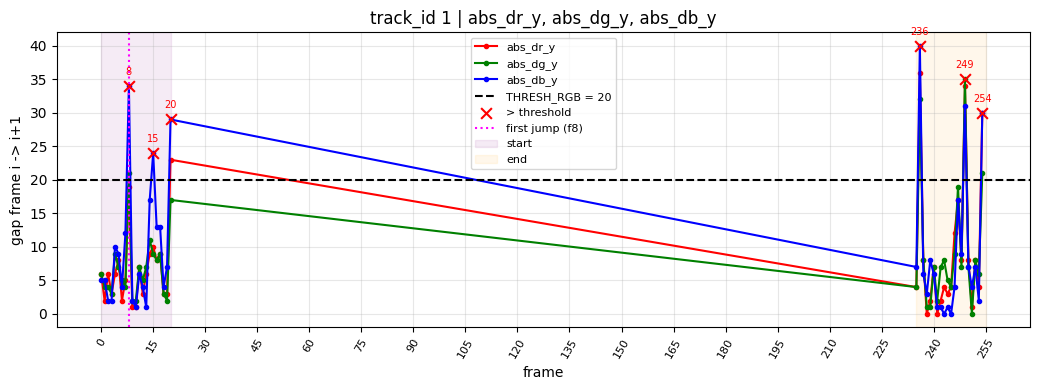

KeyboardInterrupt: 

In [ ]:
from matplotlib.ticker import MaxNLocator

# frame of the first jump for each original track (from `keys`)
jump_of = keys.set_index('track_id_orig')['frame_jump']

for tid, sub in df_jump.groupby('track_id_orig'):
    row = resume.loc[tid]
    f0, f1 = int(row['frame_0']), int(row['frame_max'])
    fj = int(jump_of[tid]) if tid in jump_of.index else None

    print(f"\n=== track_id {tid} | max gap={row['dist']:.0f} "
          f"(dr={row['dr']:.0f}, dg={row['dg']:.0f}, db={row['db']:.0f}) | "
          f"track spans frames {f0} -> {f1} | first jump at frame {fj} | "
          f"{sub['frame'].nunique()} frames displayed (start + end windows) ===")

    c = (sub.groupby('frame')[['abs_dr_y', 'abs_dg_y', 'abs_db_y']]
            .mean().sort_index())

    fig, ax = plt.subplots(figsize=(min(40, max(10, len(c) * 0.25)), 4))
    ax.plot(c.index, c['abs_dr_y'], 'r-o', ms=3, label='abs_dr_y')
    ax.plot(c.index, c['abs_dg_y'], 'g-o', ms=3, label='abs_dg_y')
    ax.plot(c.index, c['abs_db_y'], 'b-o', ms=3, label='abs_db_y')
    ax.axhline(THRESH_RGB, color='k', ls='--', label=f'THRESH_RGB = {THRESH_RGB}')

    exceeded = c[c.max(axis=1) > THRESH_RGB]
    ax.scatter(exceeded.index, exceeded.max(axis=1), color='red', s=60,
               marker='x', zorder=5, label='> threshold')
    for fr, val in exceeded.max(axis=1).items():
        ax.annotate(str(fr), (fr, val), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=7, color='red')

    if fj is not None:
        ax.axvline(fj, color='magenta', ls=':', label=f'first jump (f{fj})')

    end_of_start = f0 + N_AROUND
    start_of_end = f1 - N_AROUND
    if end_of_start > start_of_end:
        end_of_start = start_of_end = (f0 + f1) / 2
    ax.axvspan(f0, end_of_start, color='purple', alpha=0.08, label='start')
    ax.axvspan(start_of_end, f1, color='orange', alpha=0.08, label='end')

    ax.xaxis.set_major_locator(MaxNLocator(nbins=25, integer=True))
    ax.tick_params(axis='x', labelrotation=60, labelsize=8)
    ax.grid(True, which='major', alpha=0.3)
    ax.set_xlabel('frame')
    ax.set_ylabel('gap frame i -> i+1')
    ax.set_title(f"track_id {tid} | abs_dr_y, abs_dg_y, abs_db_y")
    ax.legend(loc='best', fontsize=8)
    plt.tight_layout()
    plt.show()

    n_batches = int(np.ceil(len(sub) / BATCH))
    for n in range(n_batches):
        display_color_jump_crops(frames_video, sub, n)

In [ ]:
# For each track_id: if a jump frame is found (e.g. frame 30)
#   => the original id keeps frames from the 1st frame up to frame 30
#   => frame 31: new track_id, frame 32: new track_id, ...
# If there is no jump: all frames keep the same id


MIN_DEP = 1      # min number of frames > THRESH_RGB in the start/end windows to split the track

# Safe to re-run: if players_df_2 was already modified, restore the original ids
if 'track_id_orig' in players_df_2.columns:
    players_df_2['track_id'] = players_df_2['track_id_orig']
players_df_2 = players_df_2.drop(columns=['track_id_orig', 'new_track_id'], errors='ignore')

# Mean color per (track_id, frame)
col = (players_df_2.groupby(['track_id', 'frame'])[['r', 'g', 'b']]
                   .mean().reset_index()
                   .sort_values(['track_id', 'frame']))

# First / last frame of each track, difference per channel
first = (col.groupby('track_id').first()
            .rename(columns={'frame': 'frame_0', 'r': 'r0', 'g': 'g0', 'b': 'b0'}))
last = (col.groupby('track_id').last()
           .rename(columns={'frame': 'frame_max', 'r': 'r1', 'g': 'g1', 'b': 'b1'}))
cmp_ = first.join(last)
cmp_ = cmp_[cmp_['frame_max'] > cmp_['frame_0']].copy()   # keep tracks with at least 2 frames
cmp_['dr'] = (cmp_['r0'] - cmp_['r1']).abs()
cmp_['dg'] = (cmp_['g0'] - cmp_['g1']).abs()
cmp_['db'] = (cmp_['b0'] - cmp_['b1']).abs()
cmp_['dist'] = cmp_[['dr', 'dg', 'db']].max(axis=1)       # largest gap among R, G, B

# Tracks whose color changes too much between frame 0 and frame max
resume = cmp_[cmp_['dist'] > THRESH_RGB].sort_values('dist', ascending=False)
tracks_id_list = resume.index.tolist()
print(f"{len(tracks_id_list)} track_id with a gap > {THRESH_RGB} between frame 0 and frame max "
      f"out of {len(cmp_)}")

# Start / end windows (no overlap); i -> i+1 gaps are computed on ALL kept
# rows of the track (start + end together)
col_t = col[col['track_id'].isin(tracks_id_list)].merge(
    resume[['frame_0', 'frame_max']], left_on='track_id', right_index=True)
start = col_t['frame'] <= col_t['frame_0'] + N_AROUND
end = (col_t['frame'] >= col_t['frame_max'] - N_AROUND) & ~start
col_t['fenetre'] = np.select([start, end], ['start', 'end'], default='')
col_t = col_t[col_t['fenetre'] != ''].sort_values(['track_id', 'frame']).copy()

g = col_t.groupby('track_id')          # before: ['track_id', 'fenetre']
for ch in ['r', 'g', 'b']:
    col_t[f'abs_d{ch}_y'] = (g[ch].shift(-1) - col_t[ch]).abs()   # gap frame i -> i+1
col_t['ecart_max'] = col_t[['abs_dr_y', 'abs_dg_y', 'abs_db_y']].max(axis=1)
col_t['depasse'] = col_t['ecart_max'] > THRESH_RGB                 # True if above threshold

# First jump (> THRESH_RGB) over start + end windows -> split right after it
dep = col_t[col_t['depasse']]                    # both windows
nb_dep = dep.groupby('track_id').size()
valides = nb_dep[nb_dep >= MIN_DEP].index

keys = (dep[dep['track_id'].isin(valides)]
        .groupby('track_id', as_index=False)['frame'].min()      # min = FIRST jump
        .rename(columns={'track_id': 'track_id_orig', 'frame': 'frame_jump'}))
keys['nb_dep'] = keys['track_id_orig'].map(nb_dep)
next_id = int(players_df_2['track_id'].max()) + 1                # first free track_id
print(f"{len(keys)} track_id split (>= {MIN_DEP} exceedances)")
print(keys.to_string(index=False))

# Apply the split to players_df_2:
#    - frames <= frame_jump: original id
#    - frames  > frame_jump: a UNIQUE new id per frame
players_df_2['track_id_orig'] = players_df_2['track_id']

m = players_df_2.merge(keys[['track_id_orig', 'frame_jump']],
                       on='track_id_orig', how='left')
after = (m['frame'] > m['frame_jump']).to_numpy()      # False for tracks that are not split

# One new id for each (original track, frame) after the jump
pairs = (m.loc[after, ['track_id_orig', 'frame']]
           .drop_duplicates()
           .sort_values(['track_id_orig', 'frame'])
           .reset_index(drop=True))
pairs['new_id'] = range(next_id, next_id + len(pairs))

m = m.merge(pairs, on=['track_id_orig', 'frame'], how='left')

players_df_2['track_id'] = np.where(after, m['new_id'].to_numpy(),
                                    m['track_id_orig'].to_numpy()).astype(int)

print(f"{players_df_2['track_id_orig'].nunique()} original ids -> "
      f"{players_df_2['track_id'].nunique()} ids")

# df_jump: only the frames of the 2 windows of the tracks with a jump
df_jump = (players_df_2[players_df_2['track_id_orig'].isin(tracks_id_list)]
           .merge(col_t[['track_id', 'frame', 'fenetre', 'abs_dr_y', 'abs_dg_y', 'abs_db_y']]
                    .rename(columns={'track_id': 'track_id_orig'}),
                  on=['track_id_orig', 'frame'], how='inner')
           .sort_values(['track_id_orig', 'frame'])
           .reset_index(drop=True))

print(f"\ndf_jump: {len(df_jump)} rows, {df_jump['track_id_orig'].nunique()} track_id, "
      f"{df_jump['frame'].nunique()} distinct frames")

# View only the frames (one row per track / frame)
resume = (df_jump[['track_id_orig', 'track_id', 'frame', 'fenetre',
                 'abs_dr_y', 'abs_dg_y', 'abs_db_y']]
        .drop_duplicates(['track_id_orig', 'frame'])
        .reset_index(drop=True))

187 track_id with a gap > 20 between frame 0 and frame max out of 313
182 track_id split (>= 1 exceedances)
 track_id_orig  frame_jump  nb_dep
             1           8       6
             2          20       1
             3           1      17
             4          20       1
             6          16       6
             8           1       4
            10           1      10
            11           8      10
            15           1       1
            16           3       2
            18          12       3
            23           8      11
            25          18       5
            26           2       7
            29           3       4
            30           5       1
            31           5      17
            37          14       2
            40          23      13
            44          23       4
            45          22       3
            50          50       5
            56          41      23
            60          46      13
            62   

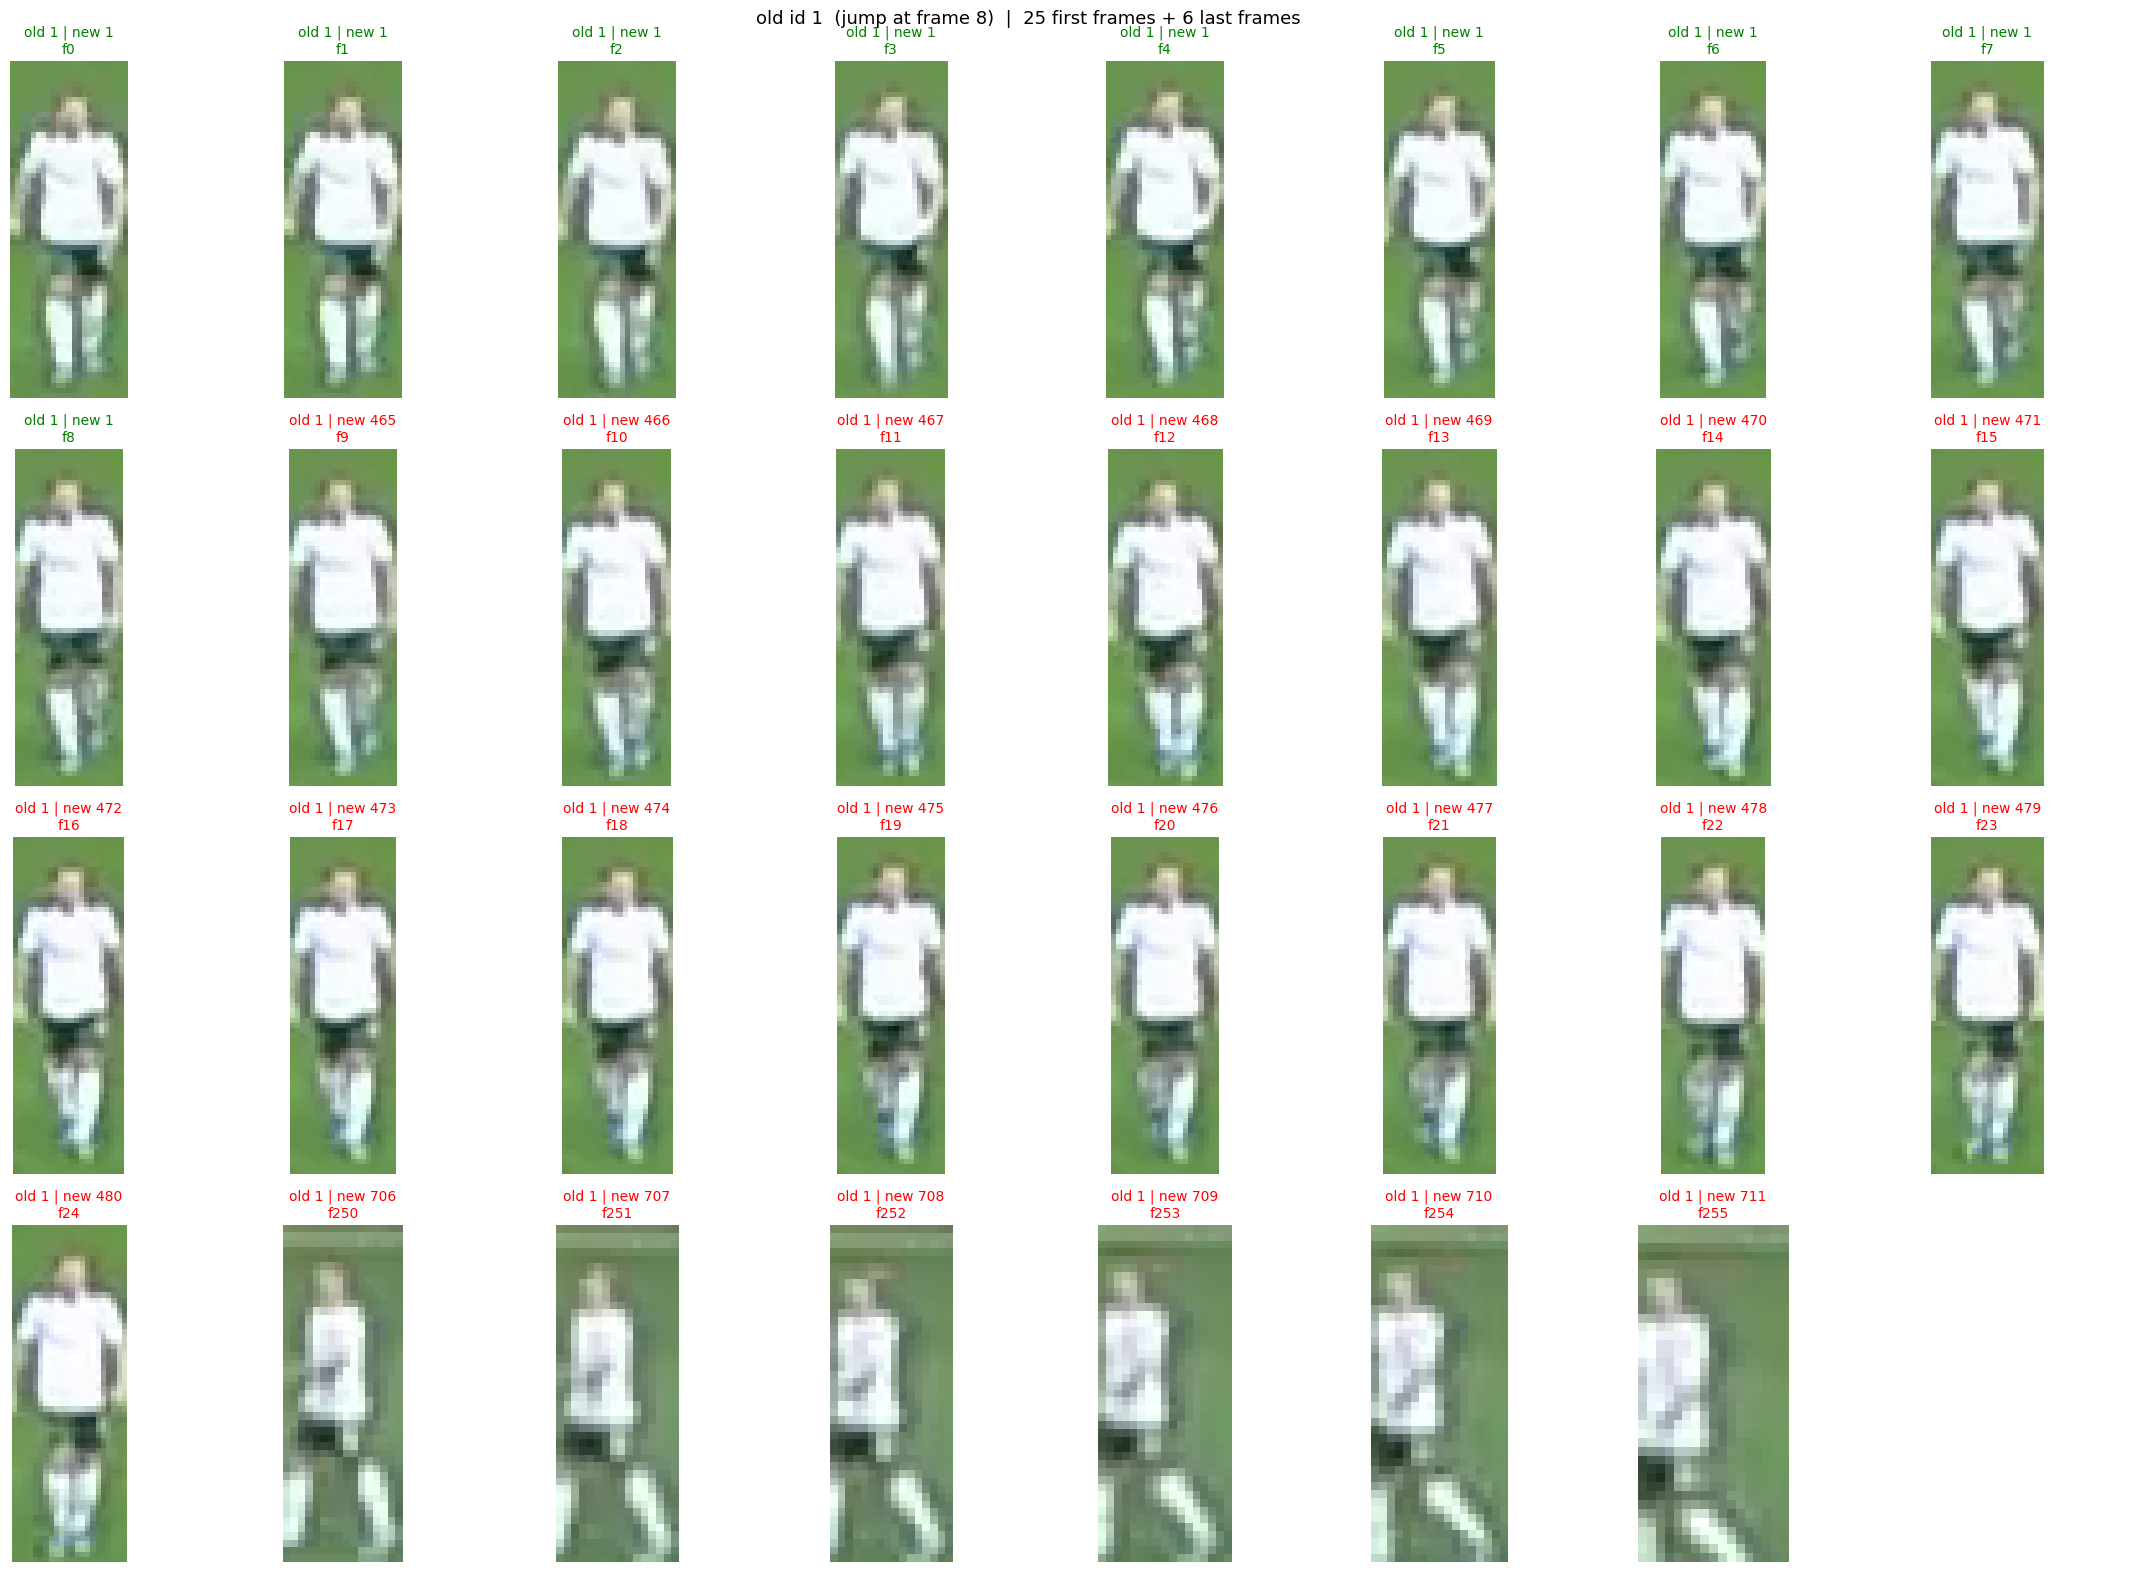

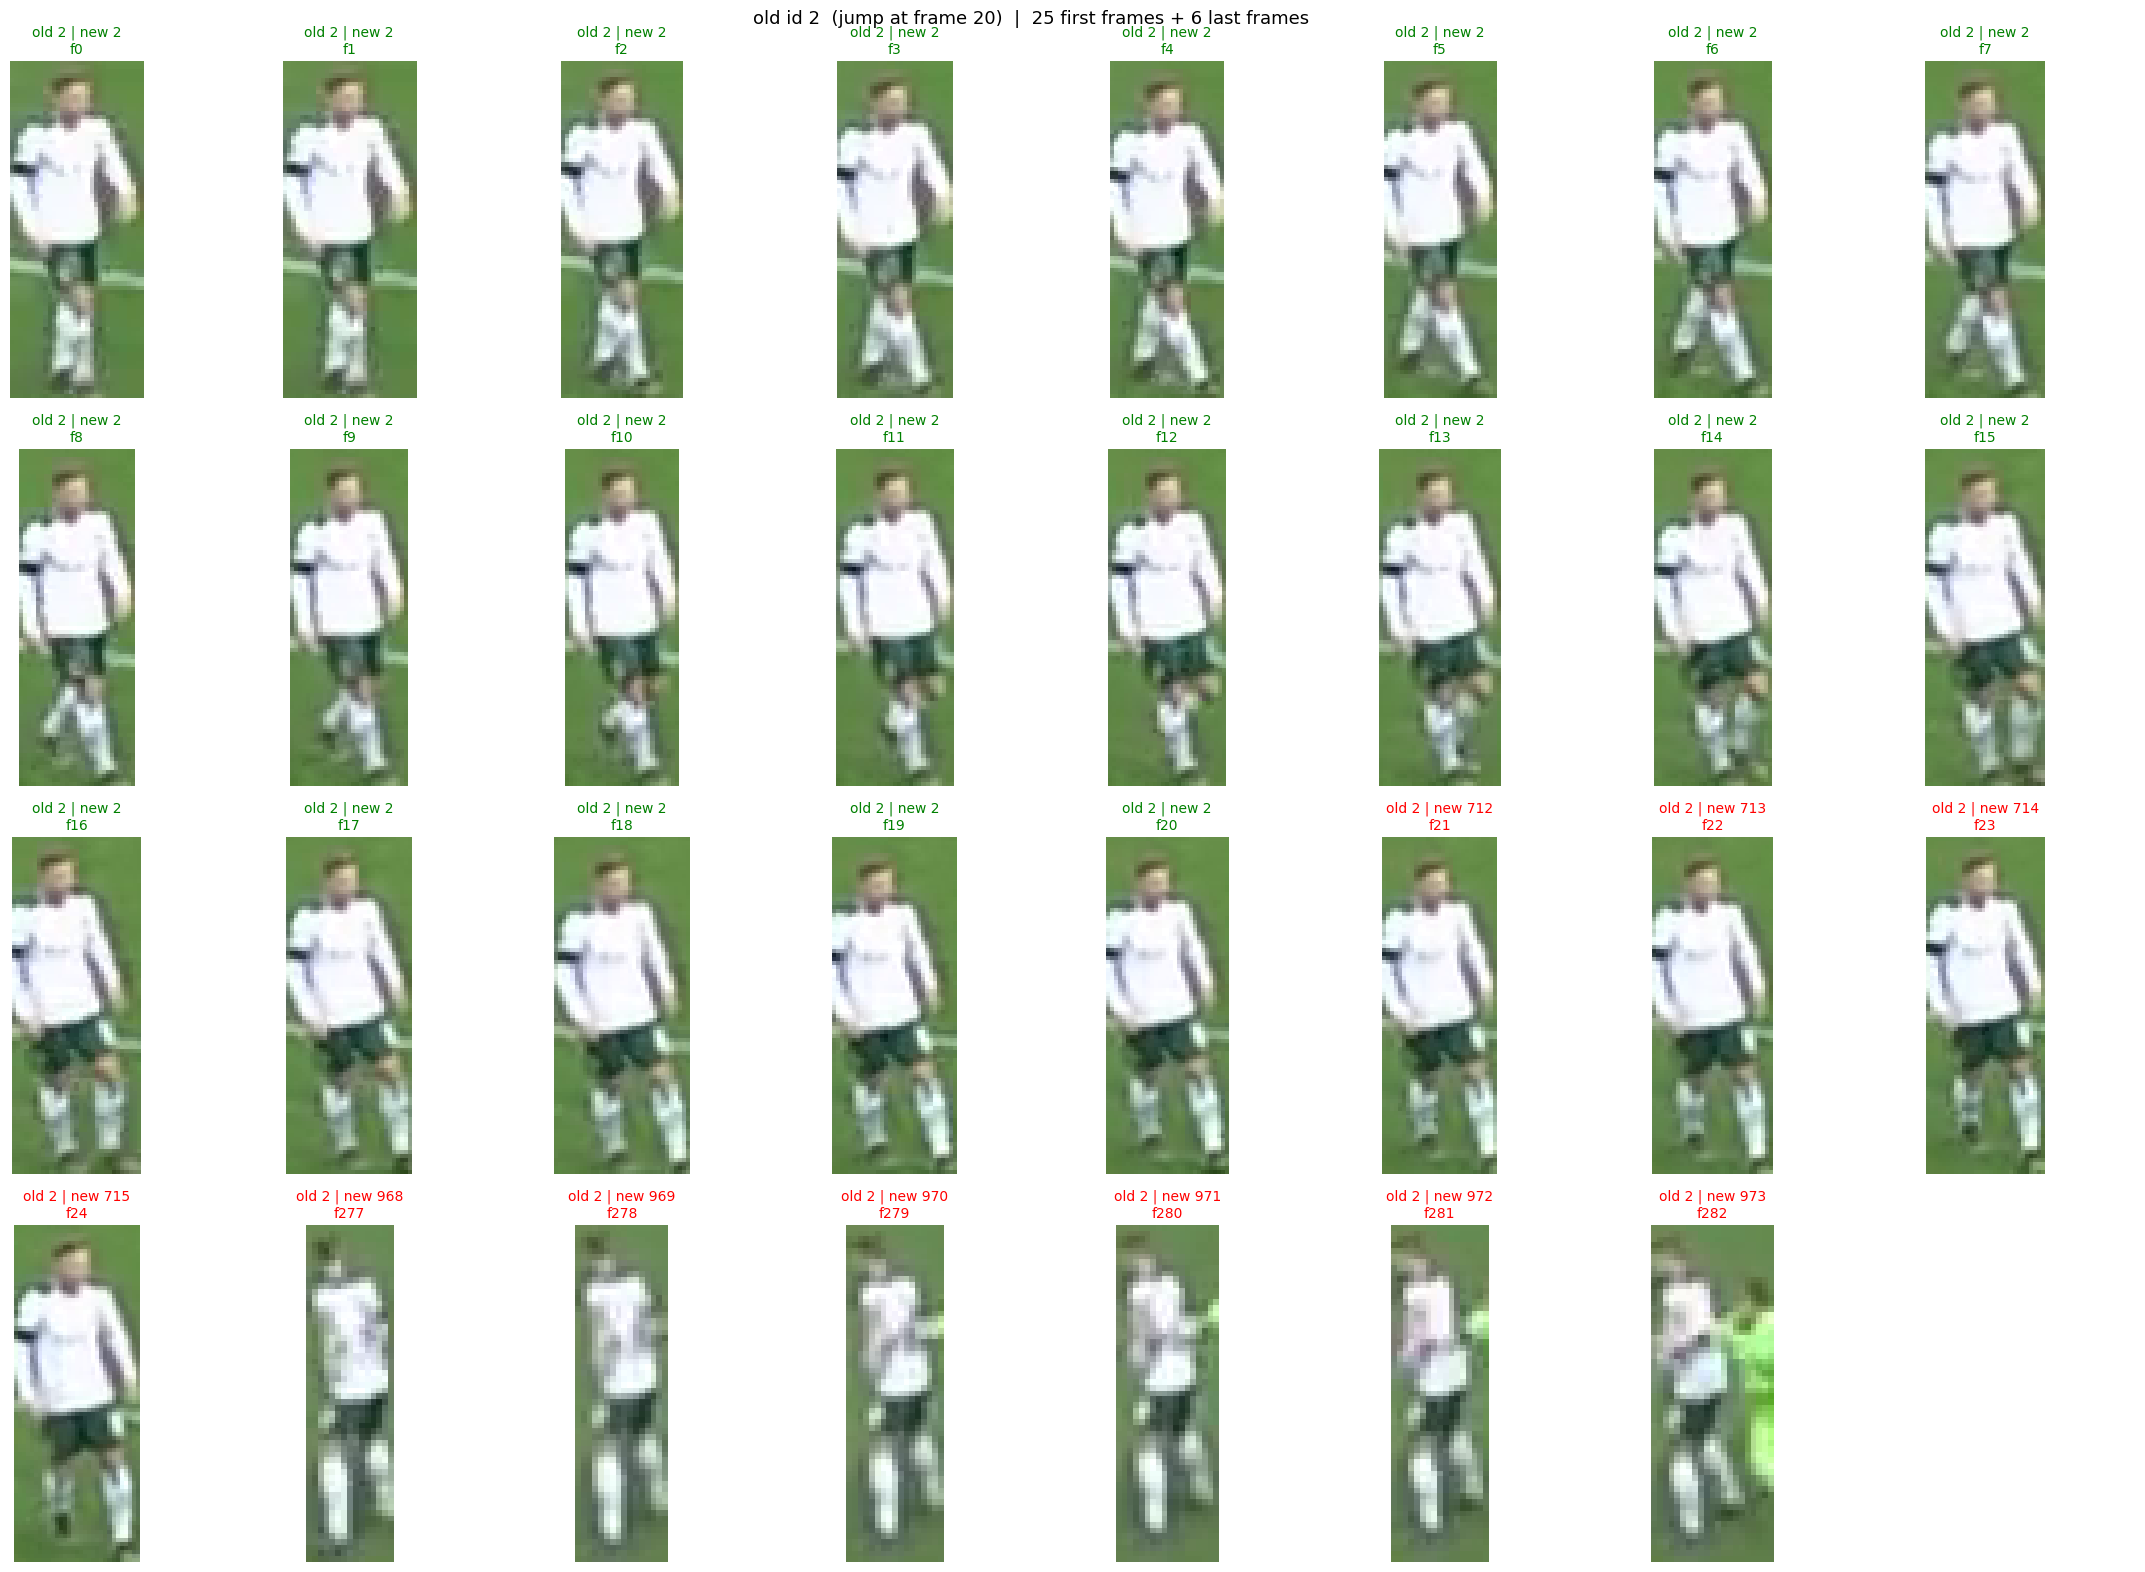

KeyboardInterrupt: 

In [ ]:
N_BEFORE = 25     # crops displayed before the jump (old id)
N_AFTER = 6       # crops displayed after the jump (one new id per frame)
COLS = 8          # images per row (lower = bigger images)
CELL_W, CELL_H = 2.8, 4.0   # size of one cell in inches

# 1. Table: old id -> new ids
new_ids = (players_df_2[players_df_2['track_id'] != players_df_2['track_id_orig']]
            .groupby('track_id_orig')
            .agg(first_new_id=('track_id', 'min'),
                 last_new_id=('track_id', 'max'),
                 nb_new_ids=('track_id', 'nunique'))
            .reset_index())

table = (keys.merge(new_ids, on='track_id_orig', how='left')
             .rename(columns={'track_id_orig': 'old_id'}))
#print(table[['old_id', 'frame_jump', 'nb_dep',
           #  'first_new_id', 'last_new_id', 'nb_new_ids']]
    #  .to_string(index=False))

# 2. For each split track: show the first N_BEFORE and last N_AFTER crops
for _, k in keys.iterrows():
    old, fs = int(k['track_id_orig']), int(k['frame_jump'])

    # One row per frame for this original track
    d = (players_df_2[players_df_2['track_id_orig'] == old]
         .drop_duplicates('frame').sort_values('frame'))

    first_rows = d.head(N_BEFORE)
    last_rows = d.tail(N_AFTER)
    rows = (pd.concat([first_rows, last_rows])
                .drop_duplicates('frame')
                .sort_values('frame'))
    if rows.empty:
        continue

    n_rows = int(np.ceil(len(rows) / COLS))
    fig, axes = plt.subplots(n_rows, COLS,
                             figsize=(CELL_W * COLS, CELL_H * n_rows),
                             squeeze=False)
    fig.suptitle(f"old id {old}  (jump at frame {fs})  |  "
                 f"{len(first_rows)} first frames + {len(last_rows)} last frames",
                 fontsize=13)

    # Hide all axes first (unused cells stay empty)
    for ax in axes.ravel():

        ax.axis('off')

    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        f = frames_video[int(r['frame'])]
        h, w = f.shape[:2]

        # Clip the bbox to the image borders
        x1, y1, x2, y2 = (int(round(v)) for v in (r['x1'], r['y1'], r['x2'], r['y2']))
        x1, x2 = max(0, min(x1, w)), max(0, min(x2, w))
        y1, y2 = max(0, min(y1, h)), max(0, min(y2, h))
        if x2 > x1 and y2 > y1:
            ax.imshow(f[y1:y2, x1:x2, ::-1])                  # BGR -> RGB

        # Red title = frame with a new id (after the jump), green = original id
        is_new = int(r['track_id']) != int(r['track_id_orig'])
        ax.set_title(f"old {old} | new {int(r['track_id'])}\nf{int(r['frame'])}",
                     fontsize=10, color='red' if is_new else 'green')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

###  4. Find a frame (reference frame) containing exactly 20 player IDs

In [ ]:
counts = players_df_2.groupby("frame").track_id.nunique()

frames_20 = counts[counts == 20].index.tolist()

print("Number of frames with exactly 20 players:", len(frames_20))
print(frames_20[:])

# Try to find 20 clear/visible IDs; I chose the 4th one
reference_frame_number = frames_20[4]
reference_frame_number

In [ ]:
reference_frame_20_player_ids = players_df_2[players_df_2["frame"] == reference_frame_number]["track_id"].unique()
reference_frame_20_player_ids

In [ ]:
tracks_copy_2 = tracks.copy()
tracks_copy_2 = {
    "players": dataframe_to_tracks(players_df_2, len(frames_video)),
    "referees": tracks["referees"],
    "ball":  dataframe_to_tracks(ball_df,  len(frames_video)),
    "goalkeeper": tracks["goalkeeper"],
}

In [ ]:
N = reference_frame_number
N1 = reference_frame_number+1
annotated = draw_annotations(frames_video[N:N1], {k: v[N:N1] for k, v in tracks_copy_2.items()})

for i in range(N1 - N):
    display(Image.fromarray(cv2.cvtColor(annotated[i], cv2.COLOR_BGR2RGB)).resize((960, 540)))

In [ ]:
#players_df_2.to_csv('players_df_before_treatment_ids.csv', index=False)

### 5. Build test sets (pipeline) to get the same player IDs across all frames

###### Test 0:  for each ID in reference_frame_20_player_ids present in frame i, compare the bbox distance between frame i and frame i+1 or i-1. If a track_id in frame i+1 or i-1 has a distance < threshold, assign this  track_id to the ID from reference_frame_20_player_ids.

In [ ]:
players_df_3 = pd.read_csv("players_df_before_treatment_ids.csv")

# Stop when there is no change (=> you can add code to break the loop when nothing changes)

for i in range(9):

    print(f"\n########## TOUR {i} ##########")

    players_df_3 = run_player_id_correction_pipeline_test_0(
        players_df_3, reference_frame_20_player_ids, reference_frame_number,
        overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)

    for tid in reference_frame_20_player_ids:
      frames = players_df_3.loc[players_df_3["track_id"] == tid, "frame"].unique()
      fs = sorted(frames)
      print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

###### Test 1: for each ID in reference_frame_20_player_ids present in frame i compare the bbox distance and RGB between frame i and frame i+n or i-n (n = max_gap). If a track_id in frame i+n or i-n has a distance and RGBbelow the threshold, assign this track_id to the ID from reference_frame_20_player_ids.

In [ ]:
for j in range(4):  # for loop until no change (we can add a line comparing the len before and after for each of the 20 IDs)
                    # i=1: no change (after the first 6 outputs from the fix_missing_players_ids_step_C function, nothing happens) => so we stop at i=0
    i=0

    players_df_3 = run_player_id_correction_pipeline_test_1(
        players_df_3, reference_frame_20_player_ids, reference_frame_number,
        i=0, n_rounds=3, verbose=False)

###### Test 2: same as Test 1, but with a larger bbox distance threshold and max_gap to search further across frames

In [ ]:
for j in range(3):

 players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=0)

In [ ]:
for j in range(2):

 players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=1)

In [ ]:
for j in range(2):

 players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=2)

In [ ]:
for j in range(2):

 players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=3)

In [ ]:
for j in range(2):

 players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=4)

In [ ]:
for j in range(1):

  players_df_3 = run_player_id_correction_pipeline_test_2(
    players_df_3, reference_frame_20_player_ids, reference_frame_number, i=5)  # when i=6 there is no change => so we stop at i=5

##### Test 3: same as Tests 1 and 2, increasing the RGB threshold value and searching far and near (max_gap) across frames with large and small bbox distance thresholds

In [ ]:
for j in range (3):

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 60,
                                        rgb_threshold_unique = 5,
                                        max_gap=10, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 30,
                                        rgb_threshold_unique = 7,
                                        max_gap=15, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )


        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 10,
                                        rgb_threshold_unique = 10,
                                        max_gap=10, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )

        players_df_3 = fix_missing_players_ids_step_C(
                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                        bbox_threshold_unique = 1,
                        rgb_threshold_unique = 250,
                        max_gap=10, nb_frame=40, nb_refs=5, max_passes=1,
                        rgb_mode = "or",verbose=False
                        )

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 50,
                                        rgb_threshold_unique = 1.1,
                                        max_gap=30, nb_frame=1, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False)

        for k in range(2):

            players_df_3 =  run_player_id_correction_pipeline_test_0(
                    players_df, reference_frame_20_player_ids, reference_frame_number,
                    overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)


        for tid in reference_frame_20_player_ids:
                                frames = players_df_3.loc[players_df_3["track_id"] == tid, "frame"].unique()
                                fs = sorted(frames)
                                print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

In [ ]:
for j in range (2):

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 60,
                                        rgb_threshold_unique = 10,
                                        max_gap=10, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 30,
                                        rgb_threshold_unique = 12,
                                        max_gap=15, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )


        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 10,
                                        rgb_threshold_unique = 15,
                                        max_gap=10, nb_frame=2, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False
                                )

        players_df_3 = fix_missing_players_ids_step_C(
                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                        bbox_threshold_unique = 1,
                        rgb_threshold_unique = 250,
                        max_gap=10, nb_frame=40, nb_refs=5, max_passes=1,
                        rgb_mode = "or",verbose=False
                        )

        players_df_3 = fix_missing_players_ids_step_C(
                                        players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                        bbox_threshold_unique = 50,
                                        rgb_threshold_unique = 1.1,
                                        max_gap=30, nb_frame=1, nb_refs=300, max_passes=1,
                                        rgb_mode = "or",verbose=False)


        for k in range(2):

            players_df_3 =  run_player_id_correction_pipeline_test_0(
                    players_df, reference_frame_20_player_ids, reference_frame_number,
                    overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)


        for tid in reference_frame_20_player_ids:
                                frames = players_df_3.loc[players_df_3["track_id"] == tid, "frame"].unique()
                                fs = sorted(frames)
                                print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

##### Test 4: some IDs do not move => search over a small max_gap with a large distance and large RGB threshold, or a large max_gap with a small distance and large RGB threshold, or a large max_gap with a large distance and small RGB threshold

In [ ]:
players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 120,
                                rgb_threshold_unique = 50,
                                max_gap=10, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)


players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 100,
                                rgb_threshold_unique = 50,
                                max_gap=20, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 80,
                                rgb_threshold_unique = 50,
                                max_gap=30, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 60,
                                rgb_threshold_unique = 50,
                                max_gap=40, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 40,
                                rgb_threshold_unique = 50,
                                max_gap=50, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 20,
                                rgb_threshold_unique = 70,
                                max_gap=20, nb_frame=40, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 10,
                                rgb_threshold_unique = 100,
                                max_gap=20, nb_frame=50, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 120,
                                rgb_threshold_unique = 10,
                                max_gap=100, nb_frame=10, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)

players_df_3 =  fix_missing_players_ids_step_C(
                                players_df_3, reference_frame_20_player_ids, reference_frame_number,
                                bbox_threshold_unique = 120,
                                rgb_threshold_unique = 20,
                                max_gap=100, nb_frame=20, nb_refs=300, max_passes=1,
                                rgb_mode = "or",verbose=False)


players_df_3 =  run_player_id_correction_pipeline_test_0(
        players_df, reference_frame_20_player_ids, reference_frame_number,
        overlap_threshold=12, step_a_max_gap=1, final_max_gap=10)

for tid in reference_frame_20_player_ids:
      frames = players_df_3.loc[players_df_3["track_id"] == tid, "frame"].unique()
      fs = sorted(frames)
      print(f"id {tid:>6} : len(frames) = {len(frames):>4}  [{fs[0]} .. {fs[-1]}]")

In [ ]:
players_df_3 = fill_short_gaps(players_df_3, reference_frame_20_player_ids, reference_frame_number, max_gap=None)

In [ ]:
# Keep only rows whose id is in the reference set, across all frames
players_df_3 = players_df_3[players_df_3["track_id"].isin( set(reference_frame_20_player_ids))].reset_index(drop=True)

In [ ]:
#players_df_3.to_csv('players_df_after_treatment_ids.csv', index=False)

##### Test (display image and video)

In [ ]:
tracks_copy_3 = tracks_copy_2.copy()

ids_to_keep = [5] # select one ID among the 20 reference player IDs to display

players_df_55 = players_df_3.copy()

players_df_55 = players_df_55[players_df_55["track_id"].isin(ids_to_keep)]

tracks_copy_3 = {
    "players": dataframe_to_tracks(players_df_55, len(frames_video)),
    "referees": tracks["referees"],
    "ball": dataframe_to_tracks(ball_df, len(frames_video)),
    "goalkeeper": tracks["goalkeeper"],
}
players_df_55["frame"].max()

In [ ]:
# Display images for frame indices 0 to 750
N = 525
N1 = 526

annotated = draw_annotations(frames_video[N:N1], {k: v[N:N1] for k, v in tracks_copy_3.items()})

for i in range(N1 - N):
    display(Image.fromarray(cv2.cvtColor(annotated[i], cv2.COLOR_BGR2RGB)).resize((960, 540)))

In [ ]:
"""
# Display all images (crops of a specific ID)

sel = players_df_55[
    (players_df_55["frame"] >= 100)
    & (players_df_55["frame"] <= 750)
    & (players_df_55["track_id"].isin(ids_to_keep))
].reset_index(drop=True)

size, columns = 48, 8
nb_batches = int(np.ceil(len(sel) / size))

for n in range(nb_batches):
    display_batch_of_crops(frames_video, sel, n, size=size, columns=columns)
"""

In [ ]:
"""
ids_to_keep = [5 , 13, 22, 49] # select one ID among the 20 reference player IDs to display

players_df_55 = players_df_3.copy()

players_df_55 = players_df_55[players_df_55["track_id"].isin(ids_to_keep)]

tracks_copy_3 = {
    "players": dataframe_to_tracks(players_df_55, len(frames_video)),
    "referees": tracks["referees"],
    "ball": dataframe_to_tracks(ball_df, len(frames_video)),
    "goalkeeper": tracks["goalkeeper"],
}

save_extracts_videos (frames_video, tracks_copy_3)

import glob
from IPython.display import Video, display

videos = sorted(glob.glob("extraits/extrait_*.mp4"))

for p in videos[:]:
    print(p)
    display(Video(p, width=900, embed=True))
"""

###   coluer

In [ ]:
from sklearn.cluster import KMeans

frame0 = players_df_3[players_df_3["frame"] == 0].dropna(subset=["r", "g", "b"]).copy()
print(len(frame0), "joueurs dans la frame 0")

rgb = frame0[["r", "g", "b"]].to_numpy(float)
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(rgb)
c1, c2 = km.cluster_centers_
frame0["cluster"] = km.labels_

print("couleur 1 (r,g,b) :", c1.round(0), f"({(km.labels_ == 0).sum()} joueurs)")
print("couleur 2 (r,g,b) :", c2.round(0), f"({(km.labels_ == 1).sum()} joueurs)")

# pastilles : une par joueur, triées par cluster, + les 2 centres
tri = frame0.sort_values("cluster")
couleurs = tri[["r", "g", "b"]].to_numpy().astype(np.uint8)[None, :, :]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 3))
ax1.imshow(couleurs, aspect="auto")
ax1.set_title("joueurs frame 0 (triés par cluster)", fontsize=9)
ax2.imshow(np.array([c1, c2]).astype(np.uint8)[None, :, :], aspect="auto")
ax2.set_title("couleur 1 | couleur 2", fontsize=9)
for ax in (ax1, ax2):
    ax.axis("off")
plt.tight_layout()
plt.show()

rgb_player_team1 = c1
rgb_player_team2 = c2